# Seoul bikes









Curso: Machine Learning

Integrantes: Juan Esteban Giraldo Giraldo / Federico Avalos Zuleta

---



Fecha de entrega: 25/10/2026

## 1. Entendimiento de negocio

### RESPUESTA DEL ESTUDIANTE: 1. Entendimiento de negocio

**1.1 Descripción del caso:**

Seúl tiene un sistema de bicicletas compartidas llamado Ttareungyi, que es operado por la administración del gobierno local. Tienen estaciones repartidas por toda la ciudad para que las personas renten y devuelvan las bicicletas por hora. El problema es que la demanda puede variar mucho según la hora, el día de la semana, las condiciones climáticas y la estación. En verano en las horas pico faltan bicicletas y en invierno sobran. Al predecir la demanda podemos prever cuántas bicicletas debemos tener disponibles en la ciudad. Los datos son registros de cada hora y van desde diciembre de 2017 hasta noviembre de 2018. Son 8.760 filas en total, pero las horas en las que el sistema estuvo funcionando son 8.465.


https://www.kaggle.com/datasets/joebeachcapital/seoul-bike-sharing?resource=download


Es un dataset real, aunque la fuente de kaggle es un re subido por un tercero, los datos originalmente fueron donados a: https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand

Son datos reales que han sido usados en estudios revisados por pares, vienen del sistema publico de bicicletas de Seoul, Corea del sur.

Sathishkumar V E, Jangwoo Park y Yongyun Cho, "Using data mining techniques for bike sharing demand prediction in metropolitan city", Computer Communications, Vol. 153, pp. 353-366, marzo 2020.

Sathishkumar V E y Yongyun Cho, "A rule-based model for Seoul Bike sharing demand prediction using weather data", European Journal of Remote Sensing, pp. 1-18, febrero 2020.



----

**1.2 Pregunta de negocio:**

# Pregunta de Negocio

¿Como podemos predecir la demanda de bicicletas por hora, con una proyeccion a futuro de 24 horas, considerando el clima, festivo, día de la semana y horas pico, para reducir escacez y oferta desmedida en el sistema?

**1.3 Reglas de negocio:**

-No se pueden poner más bicicletas de las que existen en la flota. Como no nos entregan el tamaño de la flota, asumimos que no hay restricción en este sentido y el modelo entrega la disponibilidad mínima que necesita el sistema.

-Solo se predice para días en que el sistema funciona.

-La redistribución tiene costo (camiones, personal) y capacidad limitada por turno, por eso se busca no tener que hacer reabastecimiento durante el día.

-La proyección es a 24 horas, así que el modelo depende del pronóstico del clima del día siguiente, que tiene su propio error (aunque a 24 horas es más preciso que a varios días).

-El servicio debe cubrir los picos laborales, porque perder esas rentas afecta a quien depende de la bicicleta para ir a trabajar.


**1.4 Funciones de los modelos (predictivo y prescriptivo):**

Usaremos DBSCAN como nuestro modelo descriptivo, nos va a ayudar a agrupar las horas en clusters, separando los datos en grupos que sean vecinos, y a identificar las horas atípicas (ruido).

MLP será nuestro modelo predictivo. Nos dirá cuántas bicicletas se rentarán en cada hora, teniendo en cuenta la hora, el clima, la estación, si es festivo y el día de la semana.

Y el modelo prescriptivo nos dirá cuántas bicicletas debemos tener disponibles cada día en toda la ciudad, usando el pico máximo de demanda predicho para ese día más un margen de seguridad.


**1.5 Criterio de negocio de evaluación:**

Reducir la cantidad de bicicletas sobrantes y faltantes. Actualmente sin el modelo podemos estimar cuántas bicicletas se van a rentar en cada hora basándonos en el promedio histórico de esa hora, y queremos reducir el faltante y el sobrante usando el modelo predictivo. La meta es que el total de bicicletas faltantes + sobrantes se reduzca en más de 20 % frente a planificar con el promedio de cada hora (estimado conservador). Se mide en el conjunto de prueba.




---



## 2. Preparación de los datos

### RESPUESTA DEL ESTUDIANTE: 2. Preparación de los datos

Librerias

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


---

# Dataset



In [2]:
data_train = pd.read_csv("../data/SeoulBikeData.csv",encoding='latin-1')

In [3]:
BU_data_train = pd.read_csv("../data/SeoulBikeData.csv",encoding='latin-1')

#Limpieza de datos y creacion de columnas

In [4]:
data_train = data_train[data_train["Functioning Day"] == "Yes"]

*Conversion a datetime y creacion de columnas de tiempo (Día de la semana)*

In [5]:
data_train["Date"] = pd.to_datetime(data_train["Date"], format = "%d/%m/%Y")#Convertimos la fecha a el tipo de dato datetime
data_train["Date"]

0      2017-12-01
1      2017-12-01
2      2017-12-01
3      2017-12-01
4      2017-12-01
          ...    
8755   2018-11-30
8756   2018-11-30
8757   2018-11-30
8758   2018-11-30
8759   2018-11-30
Name: Date, Length: 8465, dtype: datetime64[ns]

In [6]:
data_train["Day of week"] = data_train["Date"].dt.day_name().astype(str)#Creamos columna nueva con el día de la semana
data_train["Day of week"]
data_train["Month"] = data_train["Date"].dt.month.astype(str)#Columna nueva con el mes del año
data_train["Month"]
data_train["Year"] = data_train["Date"].dt.year.astype(str)#Columna nueva con el año
data_train["Year"]


0       2017
1       2017
2       2017
3       2017
4       2017
        ... 
8755    2018
8756    2018
8757    2018
8758    2018
8759    2018
Name: Year, Length: 8465, dtype: object

Por el analisis anteriormente entregado sabemos que no hay datos faltantes.

In [7]:
for col in data_train.select_dtypes(include='object').columns:
    print(col, data_train[col].unique())

Seasons ['Winter' 'Spring' 'Summer' 'Autumn']
Holiday ['No Holiday' 'Holiday']
Functioning Day ['Yes']
Day of week ['Friday' 'Saturday' 'Sunday' 'Monday' 'Tuesday' 'Wednesday' 'Thursday']
Month ['12' '1' '2' '3' '4' '5' '6' '7' '8' '9' '10' '11']
Year ['2017' '2018']


In [8]:
data_train.isnull().sum()

Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
Day of week                  0
Month                        0
Year                         0
dtype: int64

Tampoco hay duplicados

#Tipos de datos incorrectos

In [9]:
data_train.dtypes

Date                         datetime64[ns]
Rented Bike Count                     int64
Hour                                  int64
Temperature(°C)                     float64
Humidity(%)                           int64
Wind speed (m/s)                    float64
Visibility (10m)                      int64
Dew point temperature(°C)           float64
Solar Radiation (MJ/m2)             float64
Rainfall(mm)                        float64
Snowfall (cm)                       float64
Seasons                              object
Holiday                              object
Functioning Day                      object
Day of week                          object
Month                                object
Year                                 object
dtype: object

---

In [10]:
data_train.describe()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8465,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.00000,8465.000000
mean,2018-05-28 09:14:23.744831744,729.156999,11.507029,12.771057,58.147194,1.725883,1433.873479,3.944997,0.567868,0.14912,0.077685
min,2017-12-01 00:00:00,2.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.00000,0.000000
25%,2018-02-27 00:00:00,214.000000,6.000000,3.000000,42.000000,0.900000,935.000000,-5.100000,0.000000,0.00000,0.000000
50%,2018-05-28 00:00:00,542.000000,12.000000,13.500000,57.000000,1.500000,1690.000000,4.700000,0.010000,0.00000,0.000000
75%,2018-08-24 00:00:00,1084.000000,18.000000,22.700000,74.000000,2.300000,2000.000000,15.200000,0.930000,0.00000,0.000000
max,2018-11-30 00:00:00,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.00000,8.800000
std,NaN,642.351166,6.920899,12.104375,20.484839,1.034281,609.051229,13.242399,0.868245,1.12554,0.444063


In [11]:
data_train[['Humidity(%)',"Date","Hour"]][data_train['Humidity(%)'] == 0].value_counts()

Humidity(%)  Date        Hour
0            2018-05-19  7       1
             2018-05-21  2       1
                         3       1
                         4       1
                         5       1
                         6       1
                         7       1
             2018-05-22  3       1
                         4       1
                         5       1
                         6       1
             2018-05-27  5       1
                         7       1
             2018-05-28  4       1
                         5       1
                         6       1
                         7       1
Name: count, dtype: int64

In [12]:
data_train[data_train['Humidity(%)'] == 0]

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Day of week,Month,Year
4063,2018-05-19,436,7,11.4,0,1.4,2000,4.5,0.46,0.0,0.0,Spring,No Holiday,Yes,Saturday,5,2018
4106,2018-05-21,262,2,13.9,0,0.9,2000,-2.1,0.00,0.0,0.0,Spring,No Holiday,Yes,Monday,5,2018
4107,2018-05-21,165,3,13.0,0,0.8,2000,-2.5,0.00,0.0,0.0,Spring,No Holiday,Yes,Monday,5,2018
4108,2018-05-21,113,4,12.4,0,0.8,2000,-3.4,0.00,0.0,0.0,Spring,No Holiday,Yes,Monday,5,2018
4109,2018-05-21,200,5,11.9,0,1.3,2000,-2.7,0.00,0.0,0.0,Spring,No Holiday,Yes,Monday,5,2018
4110,2018-05-21,467,6,11.4,0,0.9,2000,-2.0,0.03,0.0,0.0,Spring,No Holiday,Yes,Monday,5,2018
4111,2018-05-21,1135,7,12.3,0,0.9,1989,-2.7,0.48,0.0,0.0,Spring,No Holiday,Yes,Monday,5,2018
4131,2018-05-22,406,3,15.5,0,0.7,1420,10.4,0.00,0.0,0.0,Spring,Holiday,Yes,Tuesday,5,2018
4132,2018-05-22,248,4,15.6,0,0.5,1502,10.5,0.00,0.0,0.0,Spring,Holiday,Yes,Tuesday,5,2018
4133,2018-05-22,182,5,15.7,0,0.6,1610,10.6,0.00,0.0,0.0,Spring,Holiday,Yes,Tuesday,5,2018


#Imputacion

Humedad nunca debería de ser 0.

Nuestro razonamiento para interpolar es que la humedad sigue un ciclo de 24 horas, por lo que no se puede interpolar hacía adelante simplemente, lo que haremos es basarnos en la hora del día anterior más cercano sin dato erroneo, y interpolar hacía adelante hasta la hora del día siguente que no tenga dato erroneo.




In [13]:
data_train["Humidity(%)"] = data_train["Humidity(%)"].replace(0,np.nan)#Remplazamos los valores 0 por nan para realizar interpolacion

data_train["Humidity(%)"] = data_train.groupby("Hour")["Humidity(%)"].transform(lambda x: x.interpolate(method='linear'))#Interpolamos en base a la hora, de forma lineal.
data_train['Humidity(%)'][data_train['Humidity(%)'] == 0]

Series([], Name: Humidity(%), dtype: float64)

In [14]:
data_train["Humidity(%)"].describe()

count    8465.000000
mean       58.278618
std        20.322938
min        10.000000
25%        42.000000
50%        57.000000
75%        74.000000
max        98.000000
Name: Humidity(%), dtype: float64

**2.1 Tabla de variables de entrada:**

In [15]:
# Tabla de variables de entrada del modelo (formato pedido en la sección 2.1 de la guía)
# Los rangos salen del describe() de data_train después de la limpieza
tabla_entrada = pd.DataFrame({
    "Variable": [
        "Hour", "Temperature(°C)", "Humidity(%)",
        "Rainfall(mm)", "Snowfall (cm)", "Seasons", "Holiday", "Day of week"
    ],
    "Descripción": [
        "Hora del día en que se registran las rentas",
        "Temperatura en Seúl",
        "Humedad relativa en Seúl",
        "Precipitación acumulada en la hora",
        "Nieve acumulada en la hora",
        "Estación del año",
        "Indica si el día es festivo",
        "Día de la semana (solo se usa en la red neuronal, no en DBSCAN)"
    ],
    "Tipo": [
        "Cuantitativa discreta", "Cuantitativa continua", "Cuantitativa continua",
        "Cuantitativa continua", "Cuantitativa continua",
        "Cualitativa nominal", "Cualitativa nominal", "Cualitativa nominal"
    ],
    "Unidad": [
        "Horas", "Grados Celsius (°C)", "Porcentaje (%)",
        "Milímetros (mm)", "Centímetros (cm)", "Categórica", "Categórica", "Categórica"
    ],
    "Rango o categorías": [
        "0 a 23",
        "-17,8 a 39,4 (media 12,8)",
        "10 a 98 (media 58,3)",
        "0 a 35 (75 % de las horas = 0)",
        "0 a 8,8 (75 % de las horas = 0)",
        "Winter, Spring, Summer, Autumn",
        "Holiday, No Holiday",
        "Monday a Sunday"
    ],
    "% nulos": ["0 %"] * 8,
    "Tratamiento": [
        "Ninguno; se estandariza dentro del Pipeline",
        "Ninguno; los extremos se conservan por ser clima real",
        "Los valores en 0 % (imposibles) se reemplazaron por interpolación lineal por hora",
        "Ninguno; los atípicos se conservan por ser lluvias reales",
        "Ninguno; los atípicos se conservan por ser nevadas reales",
        "One-hot encoding",
        "One-hot encoding",
        "Creada a partir de Date; one-hot encoding"
    ]
})

display(tabla_entrada)

,Variable,Descripción,Tipo,Unidad,Rango o categorías,% nulos,Tratamiento
0,Hour,Hora del día en que se registran las rentas,Cuantitativa discreta,Horas,0 a 23,0 %,Ninguno; se estandariza dentro del Pipeline
1,Temperature(°C),Temperatura en Seúl,Cuantitativa continua,Grados Celsius (°C),"-17,8 a 39,4 (media 12,8)",0 %,Ninguno; los extremos se conservan por ser cli...
2,Humidity(%),Humedad relativa en Seúl,Cuantitativa continua,Porcentaje (%),"10 a 98 (media 58,3)",0 %,Los valores en 0 % (imposibles) se reemplazaro...
3,Rainfall(mm),Precipitación acumulada en la hora,Cuantitativa continua,Milímetros (mm),0 a 35 (75 % de las horas = 0),0 %,Ninguno; los atípicos se conservan por ser llu...
4,Snowfall (cm),Nieve acumulada en la hora,Cuantitativa continua,Centímetros (cm),"0 a 8,8 (75 % de las horas = 0)",0 %,Ninguno; los atípicos se conservan por ser nev...
5,Seasons,Estación del año,Cualitativa nominal,Categórica,"Winter, Spring, Summer, Autumn",0 %,One-hot encoding
6,Holiday,Indica si el día es festivo,Cualitativa nominal,Categórica,"Holiday, No Holiday",0 %,One-hot encoding
7,Day of week,Día de la semana (solo se usa en la red neuron...,Cualitativa nominal,Categórica,Monday a Sunday,0 %,Creada a partir de Date; one-hot encoding


# Descripcion de las variables





In [16]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

Variables = pd.DataFrame({
    "Variable": BU_data_train.columns,
    "Descripción": [
        "Fecha donde se registraron los datos",
        "Numero de bicicletas rentadas por hora en seoul",
        "Hora del día",
        "Temperatura en Seoul",
        "Humedad en seoul",
        "Velocidad del viento en seoul",
        "Visibilidad atmosferica en soeul",
        "Temperatura de punto de rocio, es la temperatura a la que debe bajar el aire para que el agua que contiene se vuelva líquida",
        "Radiacion solar recibida",
        "Cantidad de precipitacion acumulada",
        "Nieve acumulada",
        "Estacion del año",
        "Indica si es festivo",
        "Indica si el sistema de renta de bicicletas está operando"
    ],
    "Unidad": [
        "dd/mm/YY", "Unidades", "Horas [0,23]", "Celcious (°C)",
        "porcentaje (%)", "metros por segundo (m/s)", "decametros (10m)",
        "Celcious (°C)", "Megajoule por metro cuadrado (Mj/m^2)",
        "milimetros (mm)", "Centimetros (cm)", "Categorica",
        "Holiday/No Holiday", "Yes/No"
    ],
    "Tipo": [
        "Cuantitativa discreta", "Cuantitativa discreta", "Cuantitativa discreta",
        "Cuantitativa continua", "Cuantitativa continua", "Cuantitativa continua",
        "Cuantitativa continua", "Cuantitativa continua", "Cuantitativa continua",
        "Cuantitativa continua", "Cuantitativa continua", "Cualitativa nominal",
        "Cualitativa nominal", "Cualitativa nominal"
    ],
    "Rol": [
        "Variable independiente.", "Variable dependiente.", "Variable independiente.",
        "Variable independiente.", "Variable independiente.", "Variable independiente.",
        "Variable independiente.", "Variable independiente.", "Variable independiente.",
        "Variable independiente.", "Variable independiente.", "Variable independiente.",
        "Variable independiente.", "Variable independiente."
    ]
})

display(Variables)

,Variable,Descripción,Unidad,Tipo,Rol
0,Date,Fecha donde se registraron los datos,dd/mm/YY,Cuantitativa discreta,Variable independiente.
1,Rented Bike Count,Numero de bicicletas rentadas por hora en seoul,Unidades,Cuantitativa discreta,Variable dependiente.
2,Hour,Hora del día,"Horas [0,23]",Cuantitativa discreta,Variable independiente.
3,Temperature(°C),Temperatura en Seoul,Celcious (°C),Cuantitativa continua,Variable independiente.
4,Humidity(%),Humedad en seoul,porcentaje (%),Cuantitativa continua,Variable independiente.
5,Wind speed (m/s),Velocidad del viento en seoul,metros por segundo (m/s),Cuantitativa continua,Variable independiente.
6,Visibility (10m),Visibilidad atmosferica en soeul,decametros (10m),Cuantitativa continua,Variable independiente.
7,Dew point temperature(°C),"Temperatura de punto de rocio, es la temperatura a la que debe bajar el aire para que el agua que contiene se vuelva líquida",Celcious (°C),Cuantitativa continua,Variable independiente.
8,Solar Radiation (MJ/m2),Radiacion solar recibida,Megajoule por metro cuadrado (Mj/m^2),Cuantitativa continua,Variable independiente.
9,Rainfall(mm),Cantidad de precipitacion acumulada,milimetros (mm),Cuantitativa continua,Variable independiente.


---

**2.2 Variable de salida:**

Rented Bike Count, es el número de bicicletas rentadas en una hora (unidades: bicicletas/hora). Es una variable numérica discreta, por eso el problema es de regresión. En los días en que el sistema funciona va de 2 a 3,556, con una media de 729, una mediana de 542 y la distribución sesgada a la derecha.


## 3. Análisis exploratorio de datos (EDA)

### RESPUESTA DEL ESTUDIANTE: 3. EDA

#### 3.1 Dimensiones del dataset, tipos de datos y estadísticos descriptivos

In [17]:
# Dimensiones del dataset antes y después de la limpieza
print("Dataset original (filas, columnas):", BU_data_train.shape)
print("Dataset limpio, solo días en funcionamiento (filas, columnas):", data_train.shape)
print("Filas eliminadas por Functioning Day = No:", len(BU_data_train) - len(data_train))

Dataset original (filas, columnas): (8760, 14)
Dataset limpio, solo días en funcionamiento (filas, columnas): (8465, 17)
Filas eliminadas por Functioning Day = No: 295


# **Conclusion:**

El dataset original tiene 8,760 filas (una por cada hora del año) y 14 columnas. Después de quitar las 295 horas en que el sistema no estaba funcionando quedan 8,465 filas, y las columnas pasan a 17 porque creamos Day of week, Month y Year a partir de la fecha. Los tipos de datos se revisaron en la limpieza: la fecha se convirtió a datetime, las variables climáticas son numéricas y Seasons, Holiday y Day of week son categóricas.

# Resumen estadistico - Variables




In [18]:
data_train.describe()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8465,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.000000,8465.00000,8465.000000
mean,2018-05-28 09:14:23.744831744,729.156999,11.507029,12.771057,58.278618,1.725883,1433.873479,3.944997,0.567868,0.14912,0.077685
min,2017-12-01 00:00:00,2.000000,0.000000,-17.800000,10.000000,0.000000,27.000000,-30.600000,0.000000,0.00000,0.000000
25%,2018-02-27 00:00:00,214.000000,6.000000,3.000000,42.000000,0.900000,935.000000,-5.100000,0.000000,0.00000,0.000000
50%,2018-05-28 00:00:00,542.000000,12.000000,13.500000,57.000000,1.500000,1690.000000,4.700000,0.010000,0.00000,0.000000
75%,2018-08-24 00:00:00,1084.000000,18.000000,22.700000,74.000000,2.300000,2000.000000,15.200000,0.930000,0.00000,0.000000
max,2018-11-30 00:00:00,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.00000,8.800000
std,NaN,642.351166,6.920899,12.104375,20.322938,1.034281,609.051229,13.242399,0.868245,1.12554,0.444063


# Conclusiones:


**Rented Bike Count:** La media aritmetica de bicicletas rentadas es de 729, pero la desviación estándar es de 642, lo que significa que hay una variabilidad muy alta. Esto tiene sentido ya que la demanda cambia mucho según la hora y las condiciones del día. Tiene sesgo positivo, la cantidad de bicicletas rentadas normalmente no se acerca a el valor maximo de 3,556.

**Temperature(°C):** va desde -17.8°C a 39.4°C, puntos muy extremos en cuanto a condiciones climáticas, pero son valores reales del clima de Seúl (invierno y verano muy marcados). Es una variable importante para el modelo porque temperaturas muy bajas o muy altas pueden reducir el uso de las bicicletas.

**Humidity(%):** Antes de la limpieza el valor mínimo era 0%, que es imposible y seguramente era un error de medición. Esos 17 registros ya se corrigieron con interpolación, por eso ahora el mínimo es 10%.

**Visibility (10m):** El valor máximo y el percentil 75 son el mismo: 2000, seguramente es la maxima capacidad del sensor.

**Rainfall(mm) y Snowfall(cm):** Ambas variables tienen media cercana a 0 y su percentil 75 es 0, llueve muy poco y lo mismo con la nieve (que es esperado porque solo sucede en una estación). pero las pocas veces que sí pasan, pueden tener valores muy altos.

**Wind speed (m/s):** Los valores de 5 en adelante son valores atipicos


---

#**Graficas**

#### 3.2 Análisis de nulos y de su tratamiento

# Valores Faltantes




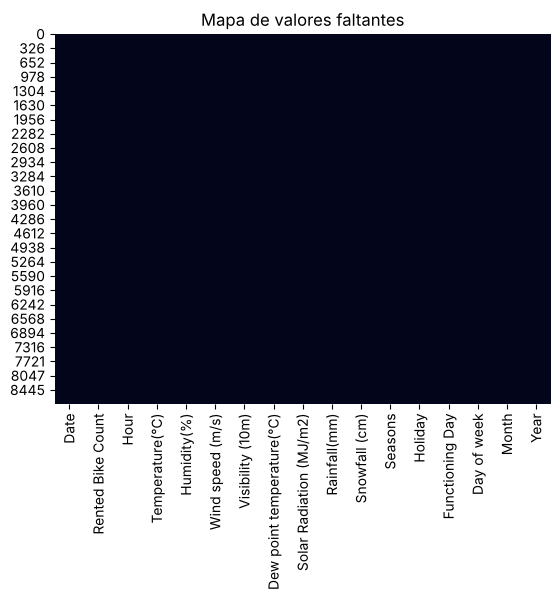

In [19]:
sns.heatmap(data_train.isnull(), cbar=False, cmap='rocket')
plt.title("Mapa de valores faltantes")
plt.show()

El mapa se muestra completamente uniforme, lo que significa que el dataset no contiene ningun valor faltante en alguna de las columnas. Los únicos datos erróneos eran los 17 registros de humedad en 0%, que no aparecen como nulos porque tenían un número, y ya se corrigieron con interpolación por hora en la etapa de limpieza. Por eso no fue necesario eliminar filas.

---


#### 3.3 Distribución de cada variable numérica (histograma y diagrama de cajas) e identificación de valores atípicos

# Outliers

Se identificaron outliers estadísticos (método IQR) en Rented Bike Count, Wind speed, Rainfall, Snowfall y Solar Radiation. Sin embargo, estos outliers no representan errores de captura ni valores imposibles, sino eventos reales y esperables dado el contexto (horas pico de demanda, eventos climáticos puntuales como tormentas o nevadas, y ráfagas de viento fuerte). Por lo tanto, no se recomienda eliminarlos ni tratarlos como datos erróneos, ya que hacerlo eliminaría información legítima y relevante para el análisis de demanda.

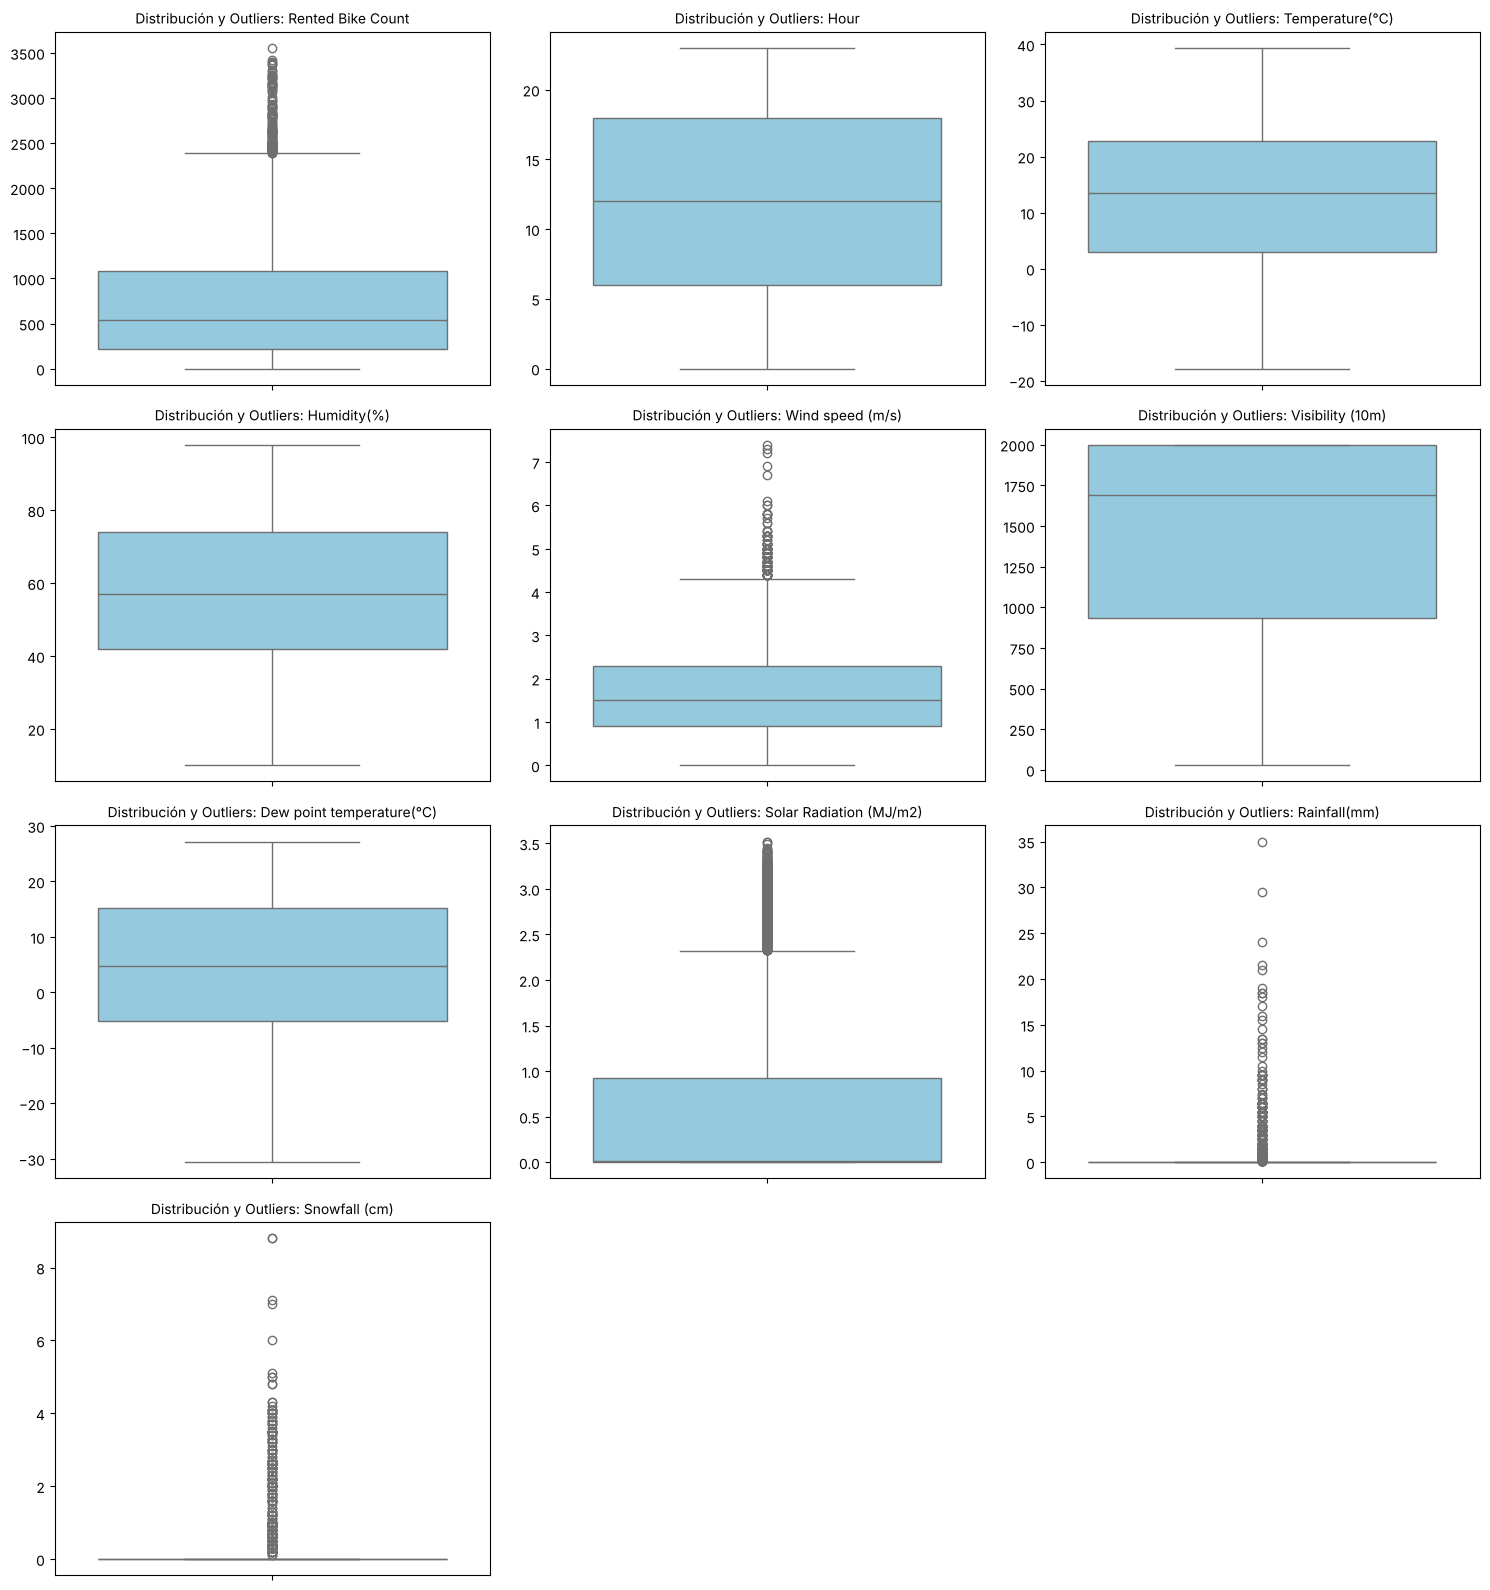

In [20]:
num_cols = data_train.select_dtypes(include=['float64', 'int64']).columns

n_cols = len(num_cols)
fig, axes = plt.subplots(nrows=(n_cols + 2) // 3, ncols=3, figsize=(15, 4 * ((n_cols + 2) // 3)))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=data_train[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribución y Outliers: {col}', fontsize=10)
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# **Conclusion Outliers:**

La **variable Rented Bike Count** presenta una distribución inclinada hacia la derecha con la presencia de valores atipicos superiores a 2300 biciletas rentadas por hora, los puntos aislados que se encuentran fuera de la caja que llegan hasta 3500 o mas corresponde a horas con mayor demanda considerada fuera de lo normal posiblemente influenciada por otras variables.

La **variable Wind speed m/s** presenta un sesgo a la derecha, indicando valores atipicos, los puntos aislados se encuentran a partir de 4.2 m/s hasta alcanzar una velocidad de 7 m/s o mas que corresponden a eventos metereologicos reales como vientos muy fuertes auque poco comunes.

La **variable Solar Radiation MJ/m2** presenta un sesgo a la derecha, indicando valores atipicos, donde los puntos se extienden desde 2.4MJ/m2 hasta superar los 3.5 MJ/m2 que corresponden a horas donde la radiacion solar alcanzo su pico maximo.

La **variable Rainfallmm y Snowfall** presenta una asimetría extrema positiva con alta concentración en cero, esto sucede probablemente porque no llueve o cae nieve muy amenudo entonces cualquier momento en que llueva o nieve se sale de lo habitual.

Para las demás variables no se identifican valores atípicos, lo que indica que el dataset es limpio y confiable para entrenar un modelo.

**Histogramas de las variables numéricas:**

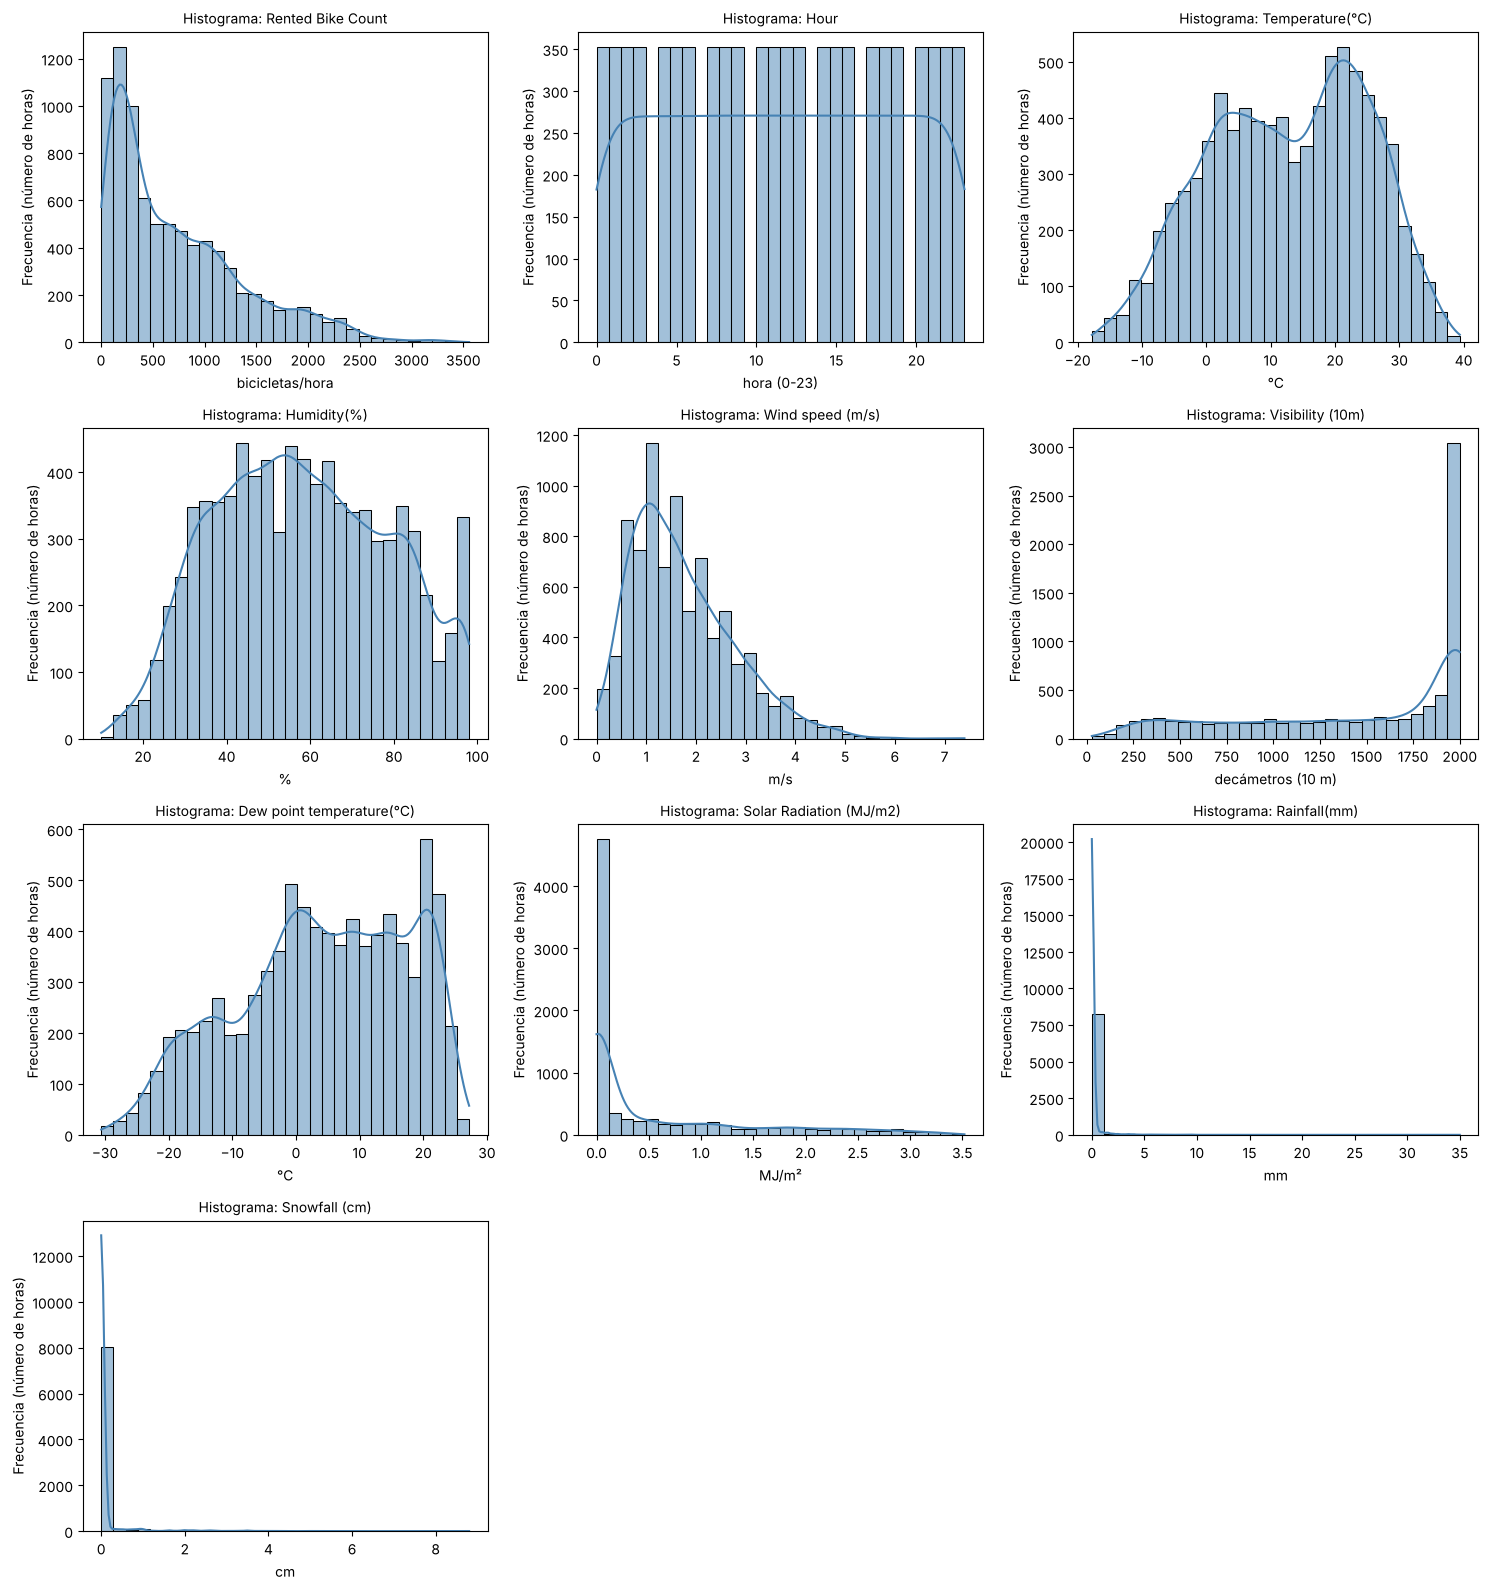

In [21]:
# Histogramas de las variables numéricas: muestran la forma de la distribución (sesgo, concentración en cero)
# que los diagramas de cajas no dejan ver
unidades = {
    "Rented Bike Count": "bicicletas/hora", "Hour": "hora (0-23)", "Temperature(°C)": "°C",
    "Humidity(%)": "%", "Wind speed (m/s)": "m/s", "Visibility (10m)": "decámetros (10 m)",
    "Dew point temperature(°C)": "°C", "Solar Radiation (MJ/m2)": "MJ/m²",
    "Rainfall(mm)": "mm", "Snowfall (cm)": "cm"
}

fig, axes = plt.subplots(nrows=(n_cols + 2) // 3, ncols=3, figsize=(15, 4 * ((n_cols + 2) // 3)))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data_train[col], bins=30, kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Histograma: {col}", fontsize=10)
    axes[i].set_xlabel(unidades.get(col, col))
    axes[i].set_ylabel("Frecuencia (número de horas)")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# **Conclusion Histogramas:**

**Rented Bike Count** tiene un sesgo a la derecha muy marcado: la mayoría de horas tienen menos de 500 rentas y muy pocas pasan de 2,500. Esto pasa porque la demanda alta solo ocurre en horas pico con buen clima. Para el modelo significa que hay pocos ejemplos de picos altos, entonces es más difícil predecirlos bien.

**Hour** es uniforme porque cada día tiene las 24 horas registradas, entonces todas las horas tienen casi la misma cantidad de datos.

**Temperature(°C)** tiene dos jorobas, una alrededor de 0-5°C y otra alrededor de 20-25°C, que corresponden a las estaciones frías y cálidas. **Dew point temperature** tiene una forma muy parecida, lo que confirma que las dos entregan casi la misma información.

**Humidity(%)** está bastante repartida entre 20% y 98%, con un pequeño grupo cerca de 95-98% que corresponde a horas con lluvia.

**Wind speed** y **Solar Radiation** están sesgadas a la derecha: casi siempre hay poco viento y la radiación es 0 en la noche, por eso esa barra tan alta en 0.

**Visibility (10m)** se acumula en 2000, lo que confirma que ese es el máximo que mide el sensor.

**Rainfall** y **Snowfall** están casi todas en 0: solo en el 6.1% de las horas llovió y en el 5.2% nevó. Como son eventos raros pero que bajan mucho la demanda, las dejamos en el modelo sin transformarlas.

#### 3.4 Frecuencias de las variables categóricas (gráfico de barras)

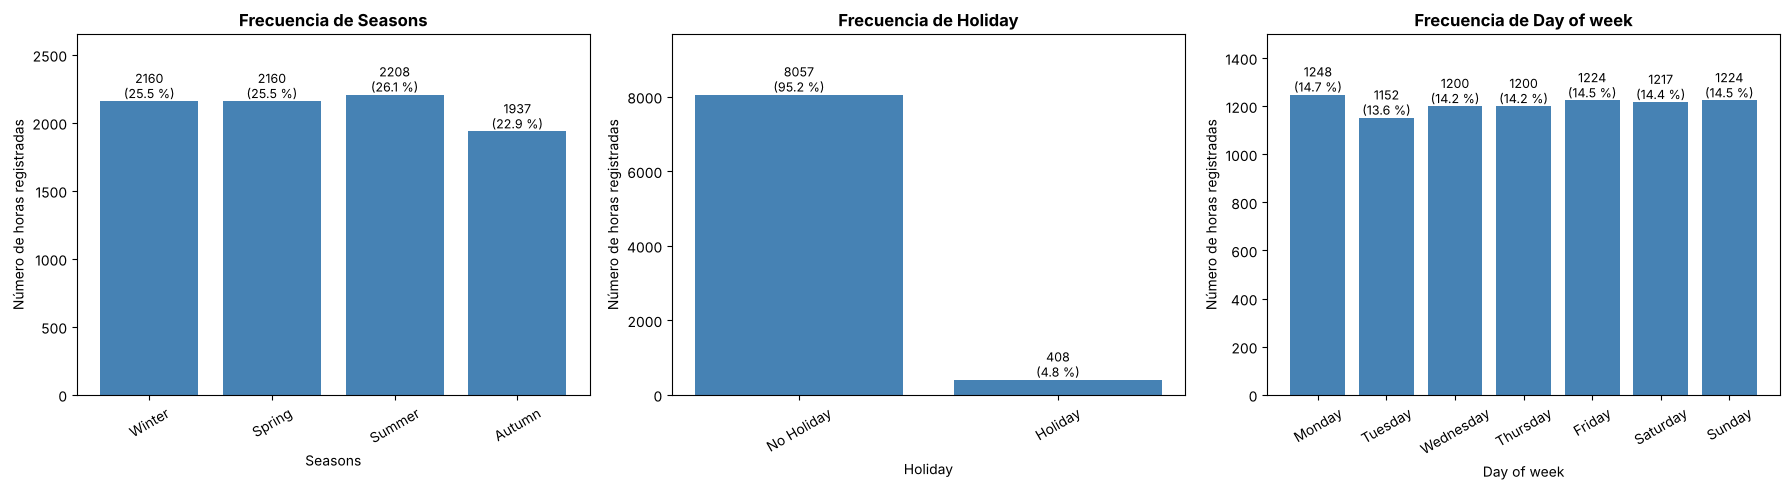

In [22]:
# Frecuencia de cada categoría: permite ver si alguna categoría tiene muy pocos registros
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
categoricas = {
    "Seasons": ["Winter", "Spring", "Summer", "Autumn"],
    "Holiday": ["No Holiday", "Holiday"],
    "Day of week": orden_dias
}

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
for i, (col, orden) in enumerate(categoricas.items()):
    conteo = data_train[col].value_counts().reindex(orden)
    axes[i].bar(conteo.index, conteo.values, color="steelblue")
    for x, v in enumerate(conteo.values):
        axes[i].text(x, v, f"{v}\n({100 * v / len(data_train):.1f} %)", ha="center", va="bottom", fontsize=9)
    axes[i].set_title(f"Frecuencia de {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Número de horas registradas")
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].set_ylim(0, conteo.max() * 1.2)

plt.tight_layout()
plt.show()

# **Conclusion:**

**Seasons** está casi balanceada: cada estación tiene alrededor del 25% de las horas, solo otoño tiene un poco menos (22.9%) porque ahí están la mayoría de los días en que el sistema no funcionó. **Day of week** también está balanceada, cada día tiene cerca del 14% de las horas.

**Holiday** sí está muy desbalanceada: solo el 4.8% de las horas (408) son festivos. Esto es normal porque hay pocos festivos en el año, pero implica que el modelo tiene pocos ejemplos de días festivos para aprender cómo cambia la demanda en esos días.

#### 3.5 Relación de las variables con la variable de salida

/tmp/ipykernel_195/2510616950.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_195/2510616950.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_195/2510616950.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


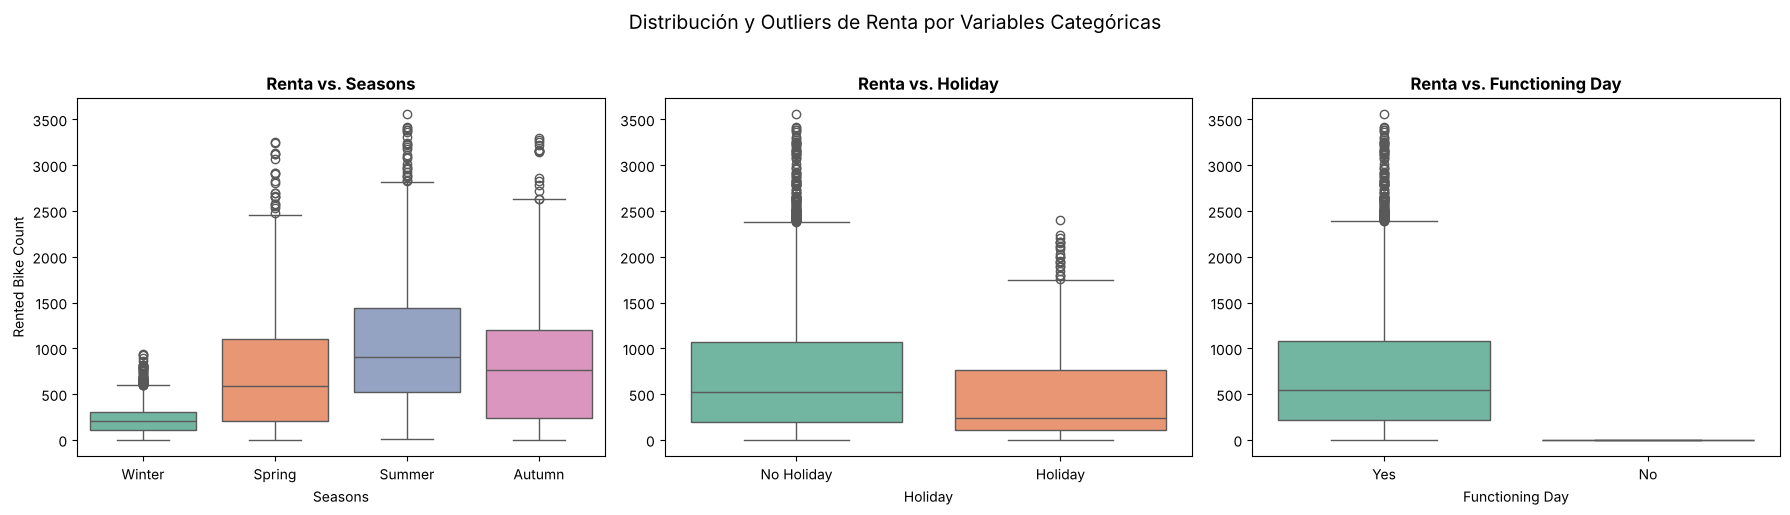

In [23]:
cat_cols = ['Seasons', 'Holiday', 'Functioning Day']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

for i, col in enumerate(cat_cols):
    sns.boxplot(
        x=col,
        y='Rented Bike Count',
        data=BU_data_train,
        ax=axes[i],
        palette='Set2'
    )
    axes[i].set_title(f'Renta vs. {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Rented Bike Count' if i == 0 else '', fontsize=10)

plt.suptitle('Distribución y Outliers de Renta por Variables Categóricas', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# **Conclusiones:**

La **variable Seasons** presenta outliers superiores en tres de sus cuatro categorías; en Summer se alcanzan los picos más extremos del dataset entre 2,800 y 3,600 bicicletas/hora, mientras que en Spring y Autumn los valores atípicos se registran a partir de las 2,500 y 2,600 unidades respectivamente. Por su parte, en Winter la demanda general es muy baja, pero presenta puntos aislados atípicos que van desde las 600 hasta casi 1,000 bicicletas/hora, correspondientes a días invernales con condiciones climáticas inusualmente favorables.

La **variable Holiday** muestra que prácticamente la totalidad de los outliers de alta demanda puntos aislados que van desde las 2,400 hasta superar las 3,500 bicicletas rentadas por hora se concentran en los días No Holiday días no festivos, lo que indica que los picos extraordinarios de alquiler responden al transporte rutinario y laboral. En los días Holiday, los valores atípicos son sustancialmente menores y solo alcanzan un máximo cercano a las 2,400 unidades.

La **variable Functioning** Day no presenta ningún valor atípico en la categoría No, ya que cuando el sistema no está operativo la renta es estrictamente 0 en todos sus registros. En cambio, en la categoría Yes se concentran todos los outliers superiores del sistema desde 2,400 hasta más de 3,500 bicicletas/hora, los cuales corresponden a las horas operativas de máxima exigencia y congestión en la ciudad.

---

# Relacion entre bicicletas rentadas y la hora

/tmp/ipykernel_195/2074894336.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = "Hour", y = "Rented Bike Count",data=data_train,palette='viridis')


Text(0.5, 1.0, 'Relacion entre bicicletas rentadas y la hora')

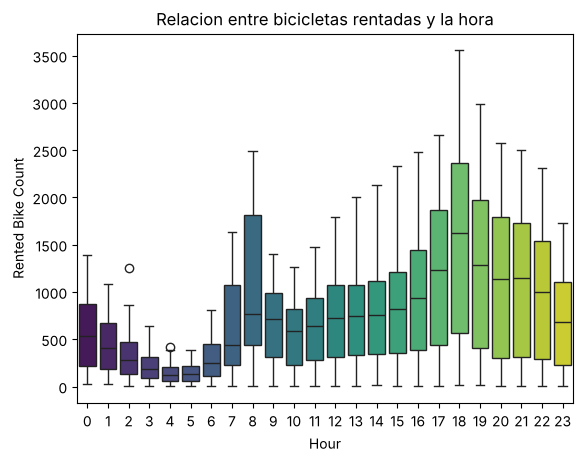

In [24]:
sns.boxplot(x = "Hour", y = "Rented Bike Count",data=data_train,palette='viridis')
plt.title("Relacion entre bicicletas rentadas y la hora")

# **Conclusion:**
La demanda de bicicletas varía  a lo largo del día y muestra dos picos de uso máximo: el primero alrededor de las 8:00 AM y el segundo, de mayor volumen, a las 6:00 PM que normalmente es la salida laboral. Durante la madrugada de 3:00 AM a 5:00 AM el alquiler cae a sus niveles mínimos, mientras que en la tarde-noche se mantiene un consumo elevado y constante antes de descender progresivamente hacia medianoche.


# Relacion entre bicicletas rentadas y la temperatura

<Axes: title={'center': 'Relacion entre bicicletas rentadas y la temperatura'}, xlabel='Temperature(°C)', ylabel='Rented Bike Count'>

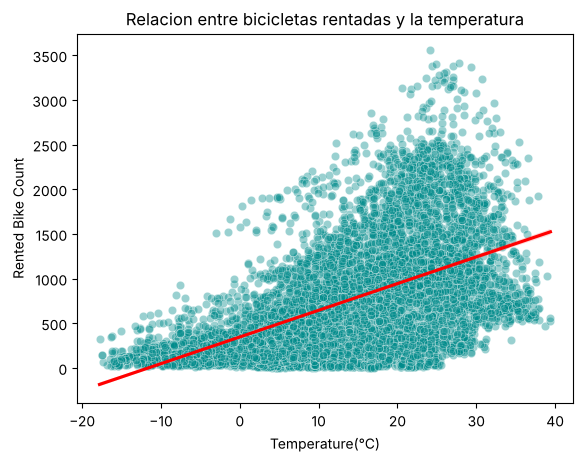

In [25]:
sns.scatterplot(x = "Temperature(°C)", y = "Rented Bike Count",data=data_train,alpha = 0.4,color="darkcyan")
plt.title("Relacion entre bicicletas rentadas y la temperatura")
sns.regplot(x="Temperature(°C)", y="Rented Bike Count", data=data_train, scatter=False, color="red")

# **Conclusion:**

Existe una relación directa entre la temperatura y la renta de bicicletas: a medida que sube la temperatura, la demanda tiende a aumentar de forma sostenida. El pico máximo de alquileres se alcanza en temperaturas cálidas entre 20 °C y 30 °C, superando las 3,500 unidades por hora. Con temperaturas minimas o bajo cero, la demanda cae a niveles mínimos.


---

# Regresion lineal simple: temperatura vs rentas (domingos a las 12:00)

In [26]:
data_train['Day of week'] = data_train["Date"].dt.day_name()

In [27]:
data_train["Day of week"]

0       Friday
1       Friday
2       Friday
3       Friday
4       Friday
         ...  
8755    Friday
8756    Friday
8757    Friday
8758    Friday
8759    Friday
Name: Day of week, Length: 8465, dtype: object

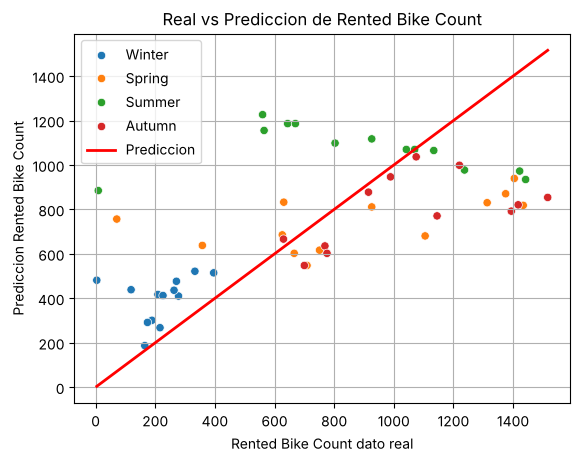

In [28]:
from sklearn.linear_model import LinearRegression

df_filter = data_train[(data_train["Hour"] == 12) & (data_train["Day of week"] == "Sunday")]
X = df_filter[["Temperature(°C)"]]
y = df_filter["Rented Bike Count"]
regressor = LinearRegression().fit(X, y)
score = regressor.score(X, y)


y_pred = regressor.predict(X)

sns.scatterplot(x=y, y=y_pred, hue=df_filter['Seasons'])
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r-', lw=2, label='Prediccion')
plt.title('Real vs Prediccion de Rented Bike Count')
plt.xlabel('Rented Bike Count dato real')
plt.ylabel('Prediccion Rented Bike Count')
plt.legend()
plt.grid(True)
plt.show()

# **Conclusion:**

Para ver si la temperatura sola alcanza para predecir, hicimos una regresión lineal solo con los domingos a las 12:00 (51 datos), así quitamos el efecto de la hora y del día. El R² es de 0.36, o sea que la temperatura sola explica apenas un 36% de la variación. En la gráfica se ve que los puntos de invierno quedan por encima de la línea (el modelo predice más de lo real) y en verano hay puntos con predicción alta pero pocas rentas reales, que probablemente son días de lluvia. Esto nos dice que la temperatura es importante pero no es suficiente, y que la relación no es lineal, por eso necesitamos un modelo que combine varias variables como la red neuronal.

---

# Relacion entre bicicletas rentadas y la humedad

<Axes: title={'center': 'Relacion entre bicicletas rentadas y la humedad'}, xlabel='Humidity(%)', ylabel='Rented Bike Count'>

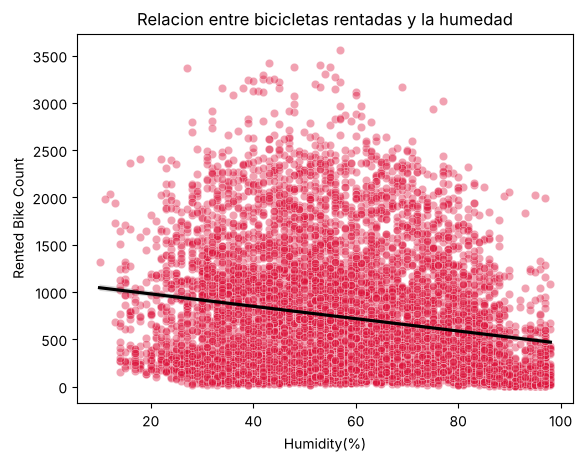

In [29]:
sns.scatterplot(x = "Humidity(%)", y = "Rented Bike Count",data=data_train,alpha = 0.4, color="crimson")
plt.title("Relacion entre bicicletas rentadas y la humedad")
sns.regplot(x="Humidity(%)", y="Rented Bike Count", data=data_train, scatter=False, color="black")

# **Conclusion:**

La relación entre la humedad y la renta de bicicletas presenta una tendencia general negativa, pero con un comportamiento no lineal, el alquiler tiene un 'punto medio ideal' entre 30% a 65% de humedad donde alcanza su máximo, y disminuye tanto si la humedad es muy baja como si es excesivamente alta.. El rango óptimo donde se registran los picos más altos de alquiler más de 3,500 unidades/hora se encuentra entre el 30% y 65% de humedad. Cuando la humedad supera el 70% o 80% pueden ser ambientes pesados o con lluvia, la demanda cae drásticamente. La línea negra muestra una ligera pendiente, confirmando que a niveles extremos de humedad el uso del servicio disminuye.



---

# Relacion entre bicicletas rentadas y la velocidad del viento

/tmp/ipykernel_195/1792870844.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x = "Wind speed (m/s)", y = "Rented Bike Count",data=data_train,palette='purple')


<Axes: title={'center': 'Relacion entre bicicletas rentadas y la velocidad del viento'}, xlabel='Wind speed (m/s)', ylabel='Rented Bike Count'>

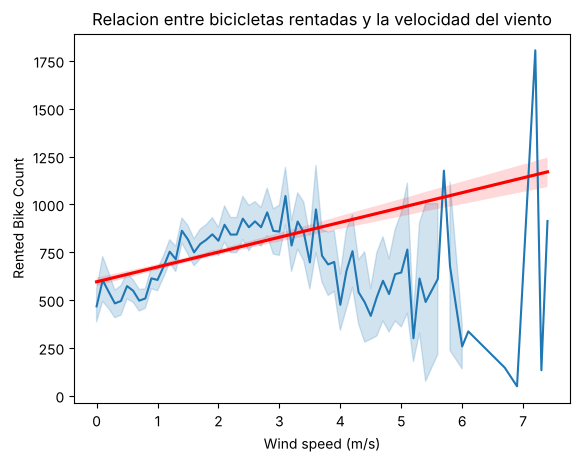

In [30]:
sns.lineplot(x = "Wind speed (m/s)", y = "Rented Bike Count",data=data_train,palette='purple')
plt.title("Relacion entre bicicletas rentadas y la velocidad del viento")
sns.regplot(x="Wind speed (m/s)", y="Rented Bike Count", data=data_train, scatter=False, color="red")

# **Conclusion:**

La gráfica muestra que un viento suave entre 1 y 3 m/s no molesta y hasta anima el alquiler, llegando casi a las 1,000 bicicletas por hora. Sin embargo, cuando el viento pasa de 4 m/s, la línea azul empieza a caer y a subir de golpe porque a la gente se le hace incómodo rodar. La línea roja sube en promedio solo por un día puntual muy raro a la derecha donde hubo viento de 7.2 m/s y muchas rentas, pero en general, cuando hay mucho viento, el uso de las bicicletas disminuye.

---

# Relación entre la Caída de Nieve (cm) y la Renta de Bicicletas

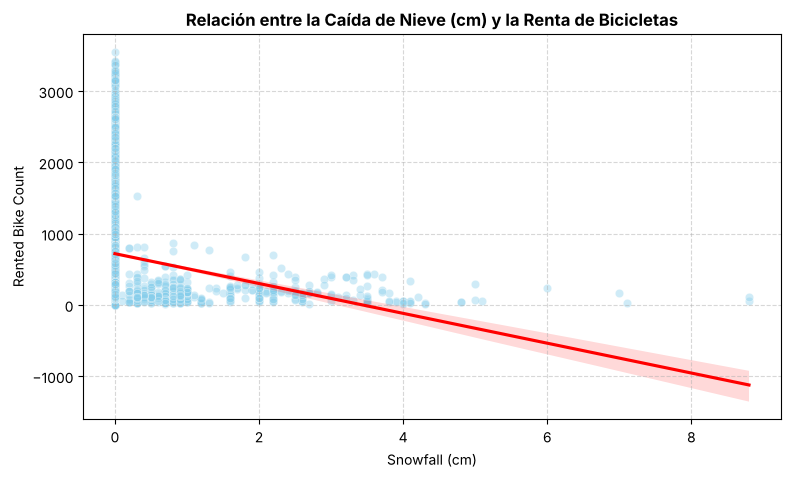

In [31]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    x='Snowfall (cm)',
    y='Rented Bike Count',
    data=BU_data_train,
    alpha=0.4,
    color='skyblue'
)
sns.regplot(
    x='Snowfall (cm)',
    y='Rented Bike Count',
    data=BU_data_train,
    scatter=False,
    color='red'
)

plt.title('Relación entre la Caída de Nieve (cm) y la Renta de Bicicletas', fontsize=12, fontweight='bold')
plt.xlabel('Snowfall (cm)', fontsize=10)
plt.ylabel('Rented Bike Count', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## **Conclusion:**
La gráfica demuestra que cuando cae nieve, la gente casi no alquila bicicletas. La inmensa mayoría de las rentas ocurren cuando no hay nada de nieve 0, alcanzando los picos más altos. Sin embargo, en cuanto empieza a nevar y se superan los 2cm, el alquiler cae casi a cero salvo por un día puntual donde hubo un consumo alto con muy poquita nieve. La línea roja en bajada confirma esta caída, confirmando que la nieve es un desincentivador crítico en la movilidad en bicicleta.

---

# Relacion entre bicicletas rentadas y la lluvia

/tmp/ipykernel_195/2552943667.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Llueve", y="Rented Bike Count", data=data_train,palette='viridis')


Text(0.5, 1.0, 'Relacion entre bicicletas rentadas y la lluvia')

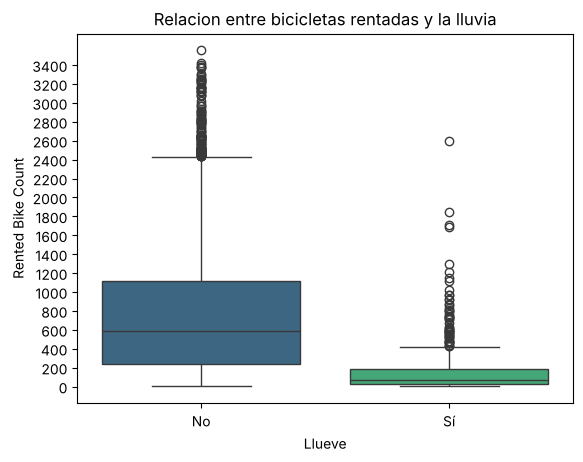

In [32]:
data_train["Llueve"] = data_train["Rainfall(mm)"].apply(lambda x: "Sí" if x > 0 else "No") #Con proposito de que la grafica tenga más sentido se pone un valor binario
sns.boxplot(x="Llueve", y="Rented Bike Count", data=data_train,palette='viridis')
plt.yticks(range(0, 3600, 200))
plt.title("Relacion entre bicicletas rentadas y la lluvia")

#**Conclusion:**
Cuando no llueve la mediana de bicicletas rentadas está cerca 600, mientras que en horas con lluvia baja a menos de 100. Además, la variabilidad cuando llueve es muy baja, entonces la lluvia es un factor que reduce la demanda de forma consistente. Es una variable clave para el modelo.


---

# Promedio de Bicicletas Rentadas por Estación

/tmp/ipykernel_195/2707450802.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


/tmp/ipykernel_195/2707450802.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


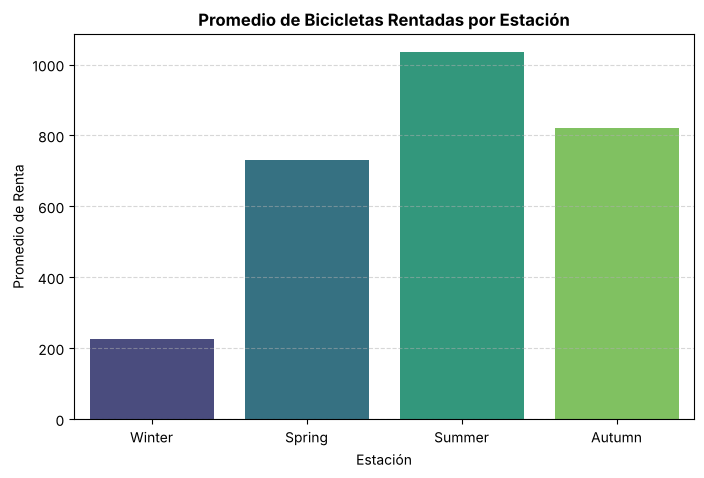

In [33]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='Seasons',
    y='Rented Bike Count',
    data=BU_data_train,
    palette='viridis',
    ci=None # Elimina las barras de error si solo quieres ver la media limpia
)
plt.title('Promedio de Bicicletas Rentadas por Estación', fontsize=12, fontweight='bold')
plt.xlabel('Estación', fontsize=10)
plt.ylabel('Promedio de Renta', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# **Conclusion:**

El uso de bicicletas cambia mucho según la época del año. En verano es cuando más se alquilan bicicletas con un promedio por encima de las 1,000 por hora, mientras que en otoño y primavera el consumo se mantiene bueno. El invierno es la estación con menor movimiento, donde el alquiler promedio cae a su punto más bajo un poco más de 200 por hora debido a las bajas temperaturas.

---

# Distribucion de rentas cuando es festivo

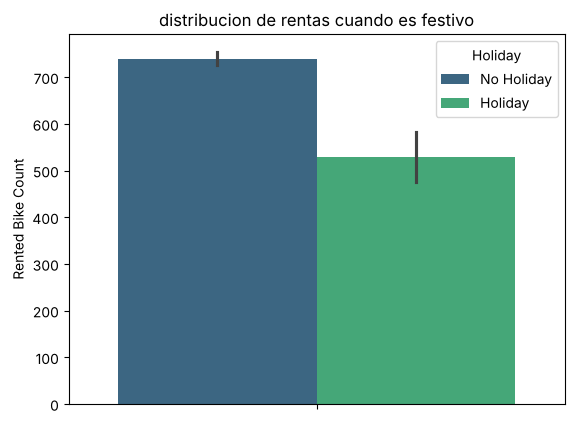

In [34]:
sns.barplot(data= data_train, y = "Rented Bike Count", hue="Holiday",palette='viridis' )
plt.title("distribucion de rentas cuando es festivo")
plt.show()


# **Conclusion:**
En días festivos el promedio de bicicletas rentadas está cerca a 500, y en los días normales es de 700. Se sabe entonces que en festivos la gente no tiene la misma necesidad de salir, por lo que el uso de las bicicletas se reduce.
Es una variable relevante para el modelo porque afecta la demanda en 200 rentas en promedio.

---

# Relacion entre bicicletas rentadas, la hora y el día de la semana

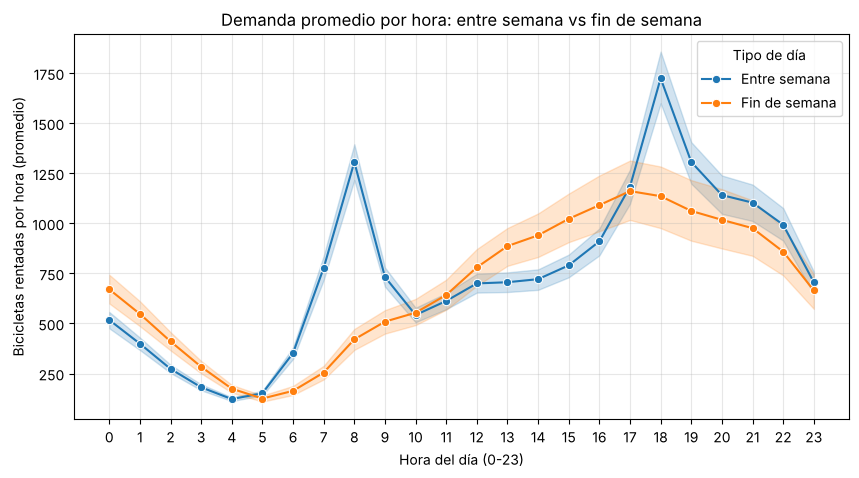

In [35]:
# Perfil horario promedio: entre semana vs fin de semana
# Se compara la forma de la curva, porque el día de la semana cambia a qué hora se renta, no solo cuánto
perfil = data_train.assign(
    Tipo_dia=np.where(data_train["Date"].dt.dayofweek >= 5, "Fin de semana", "Entre semana")
)
plt.figure(figsize=(10, 5))
sns.lineplot(data=perfil, x="Hour", y="Rented Bike Count", hue="Tipo_dia", estimator="mean", marker="o")
plt.title("Demanda promedio por hora: entre semana vs fin de semana")
plt.xlabel("Hora del día (0-23)")
plt.ylabel("Bicicletas rentadas por hora (promedio)")
plt.xticks(range(0, 24))
plt.legend(title="Tipo de día")
plt.grid(alpha=0.3)
plt.show()

# **Conclusion:**

La forma de la demanda cambia totalmente entre semana y fin de semana. Entre semana aparecen los dos picos laborales: a las 8:00 AM (cerca de 1,300 bicicletas) y a las 6:00 PM (más de 1,700). En el fin de semana no hay pico en la mañana, la demanda sube poco a poco desde las 10:00 AM y llega a su máximo entre las 3:00 y las 6:00 PM con cerca de 1,150. Esto pasa porque entre semana la gente usa la bicicleta para ir y volver del trabajo, y el fin de semana para pasear.

En promedio por día la diferencia es pequeña (748 entre semana vs 682 en fin de semana), por eso en la matriz de correlación el día de la semana parece no importar. Pero lo que cambia es **a qué hora** se rentan las bicicletas, por eso decidimos incluir el día de la semana en la red neuronal.

---

#### 3.6 Matriz de correlación de las variables numéricas

# Matriz de correlacion

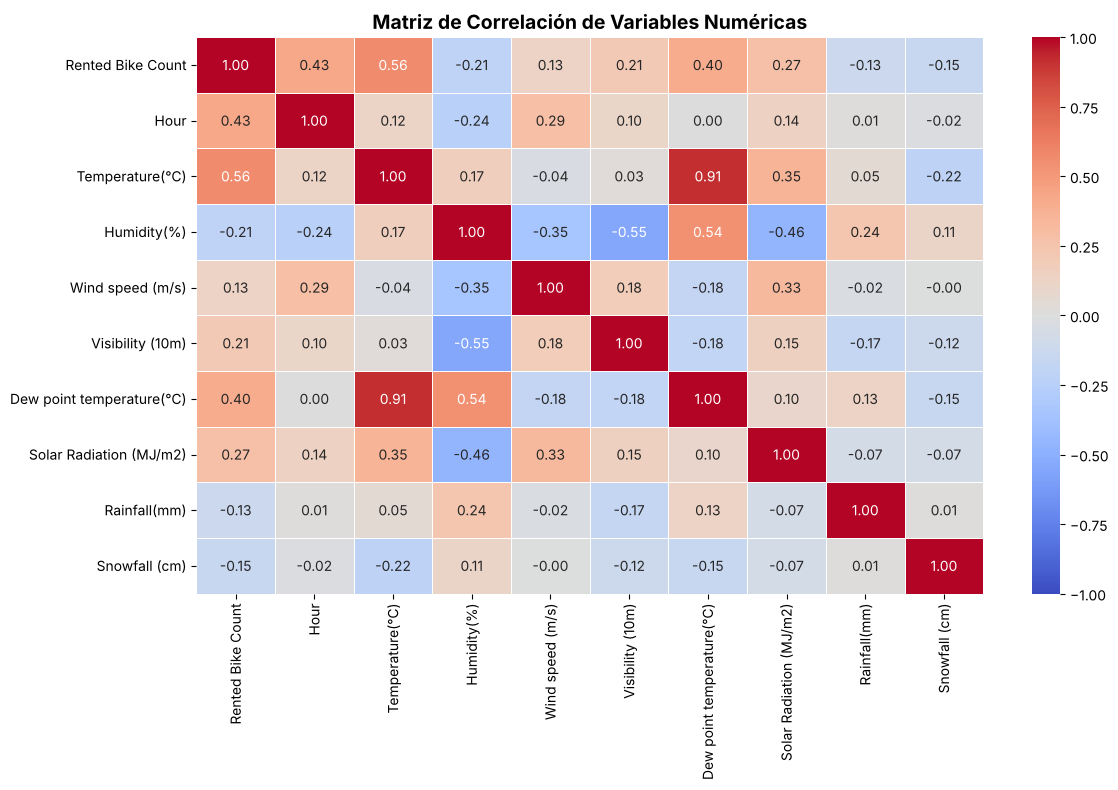

In [36]:

df_numeric = data_train.select_dtypes(include=['float64', 'int64'])

corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# **Variables con Mayor Impacto en la Renta de Bicicletas Rented Bike Count:**

**Temperature°C** Presenta la correlación positiva más fuerte con el alquiler de bicicletas con r= 0.56. A mayor temperatura ambiente, la demanda aumenta significativamente.

**Hour** muestra una relación positiva moderada con un r=0.43. Las horas del día influyen directamente en los picos de uso del servicio.

**Dew point temperature°C** con un r=0.40 y **Solar Radiation** r= 0.27 Aportan una correlación positiva moderada-baja, reflejando que los días calurosos y soleados favorecen el alquiler.

# **Variables con Impacto Negativo en la Renta:**
Tanto **Humidity** r=-0.21, **Rainfall** r=-0.13, **Snowfall** r=-0.15, presentan correlaciones negativas con la variable objetivo. Los días húmedos, con lluvia o nieve desincentivan el uso de las bicicletas.

# **Variables que no aparecen en la matriz:**
**Day of week**, **Seasons** y **Holiday** no aparecen porque son categóricas. El día de la semana por sí solo cambia poco el promedio diario de rentas, pero sí cambia la forma de la demanda durante el día, como se vio en la gráfica de entre semana vs fin de semana.

# **Otras Variables:**
Existe una multicolinealidad muy alta entre la Temperatura y el Punto de Rocío r=0.91. Esto significa que ambas variables entregan información casi idéntica. Para evitar redundancia de datos e inestabilidad en los modelos numéricos, es recomendable conservar únicamente la Temperatura y descartar el Punto de Rocío.


---

#### 3.7 Balance de clases de la variable de salida (si es clasificación)

No aplica a nuestro caso porque nuestra variable de salida es numérica y el problema es de regresión, no de clasificación. El balance de clases solo se revisa cuando la salida son categorías, y por eso tampoco usamos SMOTE. Lo que sí revisamos es la distribución de Rented Bike Count: está sesgada a la derecha (media 729, con pocos picos por encima de 2,500 bicicletas/hora), así que el modelo puede quedarse corto en las horas pico. Esto se revisa en la evaluación con el gráfico de residuales.


#### Cierre del EDA

# **Selección de Variables para el Modelo**



Basandonos en el análisis, las gráficas y la matriz de correlación, las variables candidatas para el modelo son:

# **Variables seleccionadas:**

- **Hour (r=0.43):** Es una de las variables con más peso en la demanda, con picos a las 8am y 6pm.

- **Temperature°C (r=0.56):** Es la variable con más correlación
positiva del dataset. cuando hay más temperatura, hay más demanda, tiene su pico entre 20°C y 30°C.

- **Humidity(%) (r=-0.21):** Correlación negativa. Niveles
extremos de humedad hacen que haya menos demanda.

- **Rainfall(mm) (r=-0.13):** Cuando llueve la mediana de rentas cae de casi 600 a menos de 100. Es una variable que desincentiva el uso de bicicletas.

- **Snowfall(cm) (r=-0.15):** La nieve baja la demanda casi a 0. Es una variable muy importante en meses de invierno.

- **Seasons:** El verano hay más de 1,000 bicicletas promedio por hora pero en el invierno baja a 200.

- **Holiday:** Los días festivos reducen el promedio de rentas de 739 a 529.

- **Day of week:** Cambia la forma de la demanda durante el día: entre semana hay picos a las 8am y 6pm y el fin de semana la demanda se concentra en la tarde. Solo se usa en la red neuronal, no en DBSCAN.


## 4. Modelamiento

### RESPUESTA DEL ESTUDIANTE: 4. Modelamiento

**4.1 Balanceo de datos:**

Nuestro problema es de regresión para predecir la demanda de bicicletas, entonces no necesitamos aplicar SMOTE para las clases desbalanceadas.

**Modelo descriptivo (clustering):**

Para el clustering usamos las variables numéricas (Hour, Humidity, Temperature, Rainfall, Snowfall) y las dummies de Seasons y Holiday, todas estandarizadas. El día de la semana **no** se usa en DBSCAN: al convertirlo en 7 dummies y escalarlo, dos horas de días distintos quedan a una distancia de casi 4 aunque tengan el mismo clima, y DBSCAN terminaba separando los grupos solo por el día. Por eso el día de la semana solo entra en la red neuronal.

#C.4 Listas de variables

In [37]:
numerical_cols = ['Hour', 'Humidity(%)', 'Temperature(°C)', 'Rainfall(mm)', 'Snowfall (cm)']
#"Rented Bike Count"

categorical_cols = ["Seasons", "Holiday", "Day of week"]  # Day of week solo se usa en la red neuronal; se excluye de DBSCAN en C.5
Categorical_encoded_cols = []
data_model = data_train[["Date"]+numerical_cols + categorical_cols+["Rented Bike Count"] ].copy().reset_index(drop=True)


#C.5 One hot encoding

In [38]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Ajustamos el encoder con las columnas categóricas originales
encoder = OneHotEncoder(sparse_output=False)
Categorical_encoded_cols = encoder.fit_transform(data_model[categorical_cols])
all_encoded_names = list(encoder.get_feature_names_out(categorical_cols))

# Concatenamos las nuevas columnas codificadas al DataFrame
data_model = pd.concat(
    [
        data_model,
        pd.DataFrame(Categorical_encoded_cols, columns=all_encoded_names)
    ],
    axis=1
)

# Excluimos los días de la semana de 'cat_names'
cat_names = [col for col in all_encoded_names if not col.startswith('Day of week_')]
# Guardamos las columnas de día de la semana por separado
day_of_week_encoded_cols = [col for col in all_encoded_names if col.startswith('Day of week_')]

feature_cols = ["Rented Bike Count"] + list(all_encoded_names)

In [39]:
data_model

,Date,Hour,Humidity(%),Temperature(°C),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Day of week,Rented Bike Count,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Holiday_Holiday,Holiday_No Holiday,Day of week_Friday,Day of week_Monday,Day of week_Saturday,Day of week_Sunday,Day of week_Thursday,Day of week_Tuesday,Day of week_Wednesday
0,2017-12-01,0,37.0,-5.2,0.0,0.0,Winter,No Holiday,Friday,254,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2017-12-01,1,38.0,-5.5,0.0,0.0,Winter,No Holiday,Friday,204,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2017-12-01,2,39.0,-6.0,0.0,0.0,Winter,No Holiday,Friday,173,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2017-12-01,3,40.0,-6.2,0.0,0.0,Winter,No Holiday,Friday,107,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2017-12-01,4,36.0,-6.0,0.0,0.0,Winter,No Holiday,Friday,78,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8460,2018-11-30,19,34.0,4.2,0.0,0.0,Autumn,No Holiday,Friday,1003,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8461,2018-11-30,20,37.0,3.4,0.0,0.0,Autumn,No Holiday,Friday,764,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8462,2018-11-30,21,39.0,2.6,0.0,0.0,Autumn,No Holiday,Friday,694,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8463,2018-11-30,22,41.0,2.1,0.0,0.0,Autumn,No Holiday,Friday,712,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [40]:
cat_names

['Seasons_Autumn',
 'Seasons_Spring',
 'Seasons_Summer',
 'Seasons_Winter',
 'Holiday_Holiday',
 'Holiday_No Holiday']

In [41]:
variables_entrada = numerical_cols+cat_names
variable_salida = "Rented Bike Count"

#C.6 Escalado

In [42]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

cols_to_scale = variables_entrada + [variable_salida]

scaled_data = scaler.fit_transform(data_model[cols_to_scale])

data_model_scaled = pd.DataFrame(scaled_data, columns=cols_to_scale)

display(data_model_scaled.head())

,Hour,Humidity(%),Temperature(°C),Rainfall(mm),Snowfall (cm),Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Holiday_Holiday,Holiday_No Holiday,Rented Bike Count
0,-1.662748,-1.047087,-1.484762,-0.132495,-0.174951,-0.544722,-0.585308,-0.594041,1.708503,-0.225032,0.225032,-0.739759
1,-1.518249,-0.997878,-1.509548,-0.132495,-0.174951,-0.544722,-0.585308,-0.594041,1.708503,-0.225032,0.225032,-0.817603
2,-1.373751,-0.948670,-1.550858,-0.132495,-0.174951,-0.544722,-0.585308,-0.594041,1.708503,-0.225032,0.225032,-0.865866
3,-1.229252,-0.899461,-1.567382,-0.132495,-0.174951,-0.544722,-0.585308,-0.594041,1.708503,-0.225032,0.225032,-0.968619
4,-1.084754,-1.096295,-1.550858,-0.132495,-0.174951,-0.544722,-0.585308,-0.594041,1.708503,-0.225032,0.225032,-1.013769


#C.7 Clustering con DBSCAN

In [43]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
from sklearn.metrics import adjusted_rand_score

ks = np.arange(0.5, 6.4, 0.1)
inercia = []
silueta = []
unique_list = []
rand_index = []

RANDOM_STATE = 42
for e in ks:
    dbscan = DBSCAN(
    eps=e,
    min_samples=2,
    metric="euclidean"
    )


    labels = dbscan.fit_predict(data_model_scaled[variables_entrada])
    unique_list.append(np.unique(labels, return_counts=False))
    silueta.append(silhouette_score(data_model_scaled[variables_entrada], labels))
    rand_index.append(adjusted_rand_score(labels, labels))

resultados_kmeans = pd.DataFrame({
    "K": list(ks),
    "Silueta": silueta,
    "Rand_Index": rand_index
})

In [44]:
count_list = [len(i) for i in unique_list]

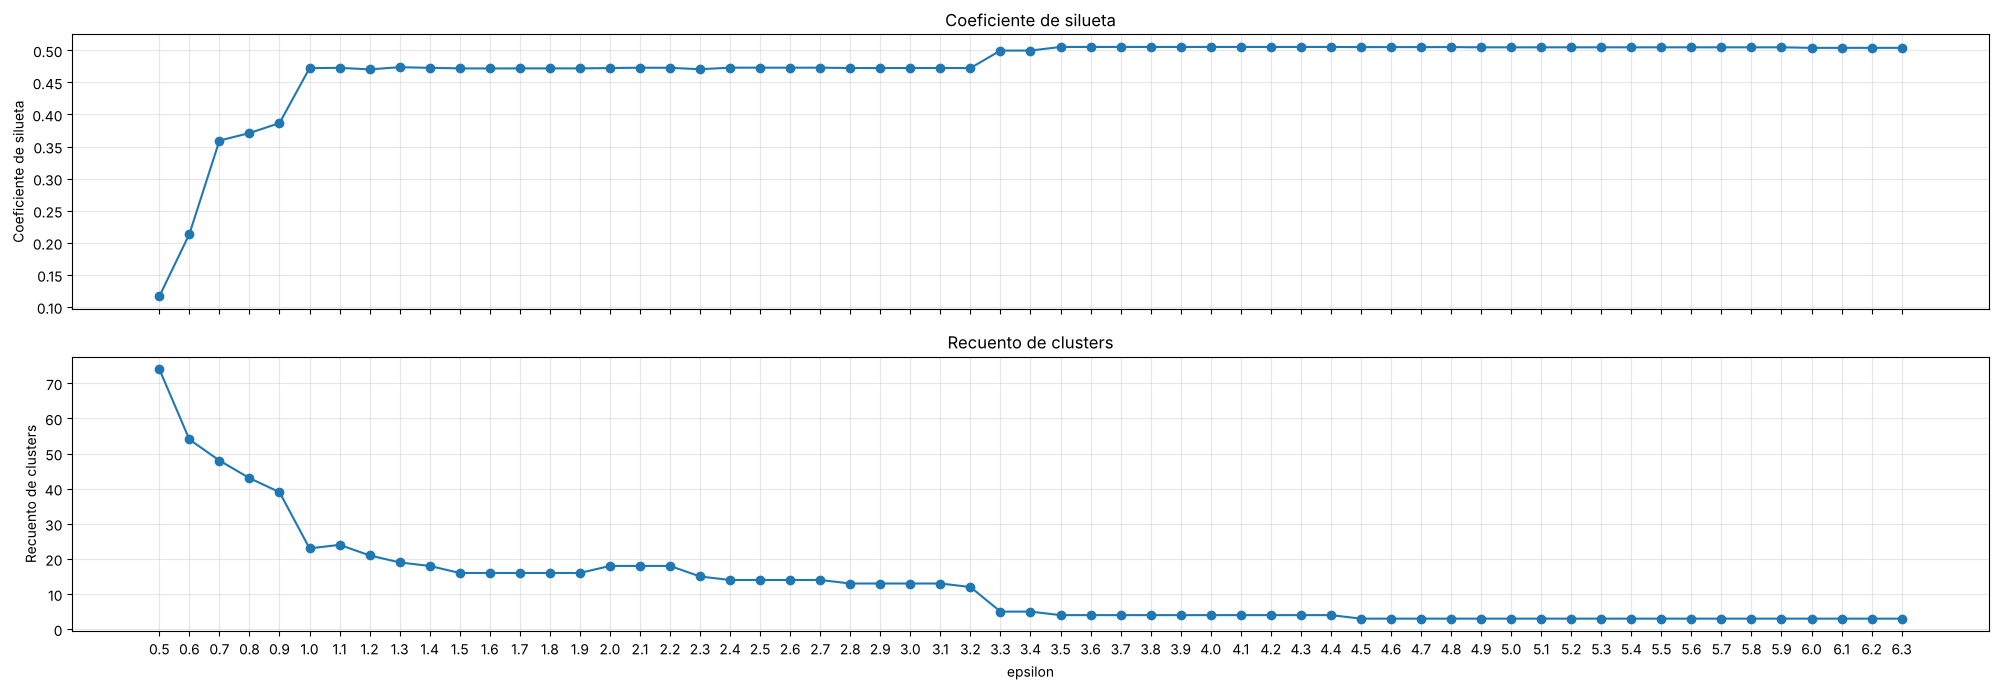

In [45]:


fig, axes = plt.subplots(2, 1, figsize=(20, 7), sharex=True)

axes[0].plot(list(ks), silueta, marker="o")
axes[0].set_ylabel("Coeficiente de silueta")
axes[0].set_title("Coeficiente de silueta")
axes[0].grid(alpha=0.3)

axes[1].plot(list(ks), count_list, marker="o")
axes[1].set_xlabel("epsilon")
axes[1].set_ylabel("Recuento de clusters")
axes[1].set_title("Recuento de clusters")
axes[1].set_xticks(list(ks))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **Conclusion:**

Con epsilon pequeño (menos de 1) DBSCAN encuentra muchísimos clusters (hasta 74) y la silueta es baja, porque casi cada grupo de horas parecidas queda separado. Entre 1.0 y 3.2 la silueta se estabiliza cerca de 0.47 y el número de clusters va bajando de 24 a 12. En 3.3 hay un salto: el número de clusters cae a 5 y la silueta sube a 0.50, porque a esa distancia DBSCAN empieza a unir estaciones distintas en un mismo grupo. Elegimos epsilon = 3.2, el último valor antes de ese salto: la silueta es casi igual a la máxima, pero los grupos todavía separan las estaciones, que en el EDA vimos que cambian mucho la demanda. Este barrido se hizo con min_samples = 2, mientras que el modelo final usa min_samples = 5.

In [46]:
from sklearn.cluster import KMeans, DBSCAN
dbscan = DBSCAN(
    eps=3.2,
    min_samples=5,
    metric="euclidean"
)

labels_dbscan = dbscan.fit_predict(data_model_scaled[variables_entrada])
n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = np.sum(labels_dbscan == -1)

print("Clusters encontrados:", n_clusters)
print("Observaciones clasificadas como ruido:", n_noise)

Clusters encontrados: 8
Observaciones clasificadas como ruido: 14


In [47]:
data_model["Cluster_DBSCAN"] = labels_dbscan


# **Conclusion:**

Con epsilon = 3.2 y min_samples = 5, DBSCAN encontró 8 clusters y clasificó 14 horas como ruido. Como se ve en el perfil más adelante, los 8 clusters corresponden a las 4 estaciones combinadas con festivo / no festivo, y el ruido son horas con clima extremo.

#C.8 Gráfico de silueta

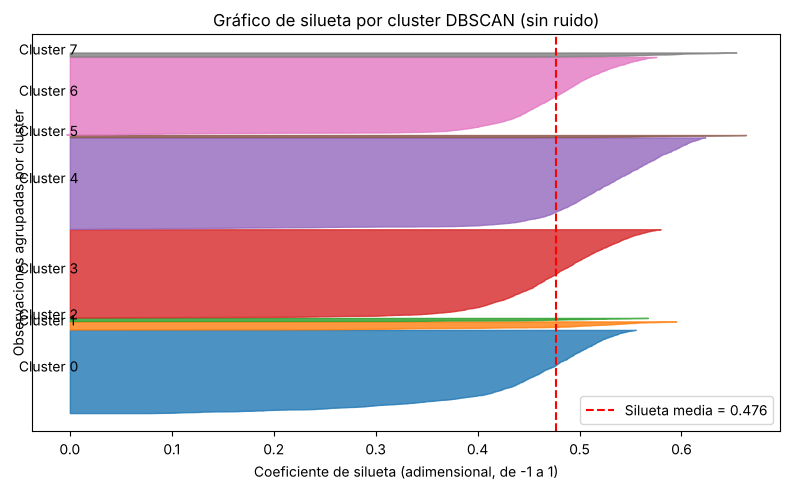

Observaciones excluidas por ser ruido: 14


In [48]:
from sklearn.metrics import silhouette_score, silhouette_samples

# Redefinimos localmente las variables con las que se ajustó el clustering
# original para evitar usar la lista global 'variables_entrada' que ahora incluye dummies de DBSCAN
variables_clustering = numerical_cols + cat_names
X_escalado = data_model_scaled[variables_clustering].values

# Silueta solo sobre los puntos que pertenecen a algún cluster: el ruido (-1)
# no es un grupo real y bajaría artificialmente el coeficiente
mascara = (data_model["Cluster_DBSCAN"] != -1).values
etiquetas = data_model.loc[mascara, "Cluster_DBSCAN"].values
X_sil = X_escalado[mascara]

if len(set(etiquetas)) >= 2:
    # Silueta media (resumen global) y silueta por punto (para ver cada cluster)
    sil_global = silhouette_score(X_sil, etiquetas)
    sil_puntos = silhouette_samples(X_sil, etiquetas)

    fig, ax = plt.subplots(figsize=(8, 5))
    y_inferior = 10
    colores = sns.color_palette("tab10", n_colors=len(set(etiquetas)))
    for i, c in enumerate(sorted(set(etiquetas))):
        # Se ordenan los valores de cada cluster para dibujar su "cuchillo" de silueta
        valores = np.sort(sil_puntos[etiquetas == c])
        y_superior = y_inferior + len(valores)
        ax.fill_betweenx(np.arange(y_inferior, y_superior), 0, valores, color=colores[i], alpha=0.8)
        ax.text(-0.05, y_inferior + 0.5 * len(valores), f"Cluster {c}")
        y_inferior = y_superior + 10  # espacio entre clusters para distinguirlos
    # La línea roja permite comparar cada cluster contra el promedio general
    ax.axvline(sil_global, color="red", linestyle="--", label=f"Silueta media = {sil_global:.3f}")
    ax.set_title("Gráfico de silueta por cluster DBSCAN (sin ruido)")
    ax.set_xlabel("Coeficiente de silueta (adimensional, de -1 a 1)")
    ax.set_ylabel("Observaciones agrupadas por cluster")
    ax.set_yticks([])
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("Observaciones excluidas por ser ruido:", (~mascara).sum())
else:
    print("Se necesitan al menos 2 clusters (sin contar el ruido) para calcular la silueta. Ajuste eps y min_samples.")

# **Conclusion:**

La silueta media es de 0.476, que es aceptable, y prácticamente ningún punto tiene silueta negativa (el mínimo es -0.003), o sea que casi no hay horas mal asignadas. Los clusters grandes (las estaciones en días no festivos) tienen la mayoría de sus puntos entre 0.40 y 0.55, y los clusters pequeños de festivos de verano y otoño tienen la silueta más alta (cerca de 0.58 en promedio), lo que indica que están bien separados del resto. La separación viene principalmente de las variables Seasons y Holiday, como se ve en el perfil de los clusters.

#C.9 Pair plot coloreado por cluster

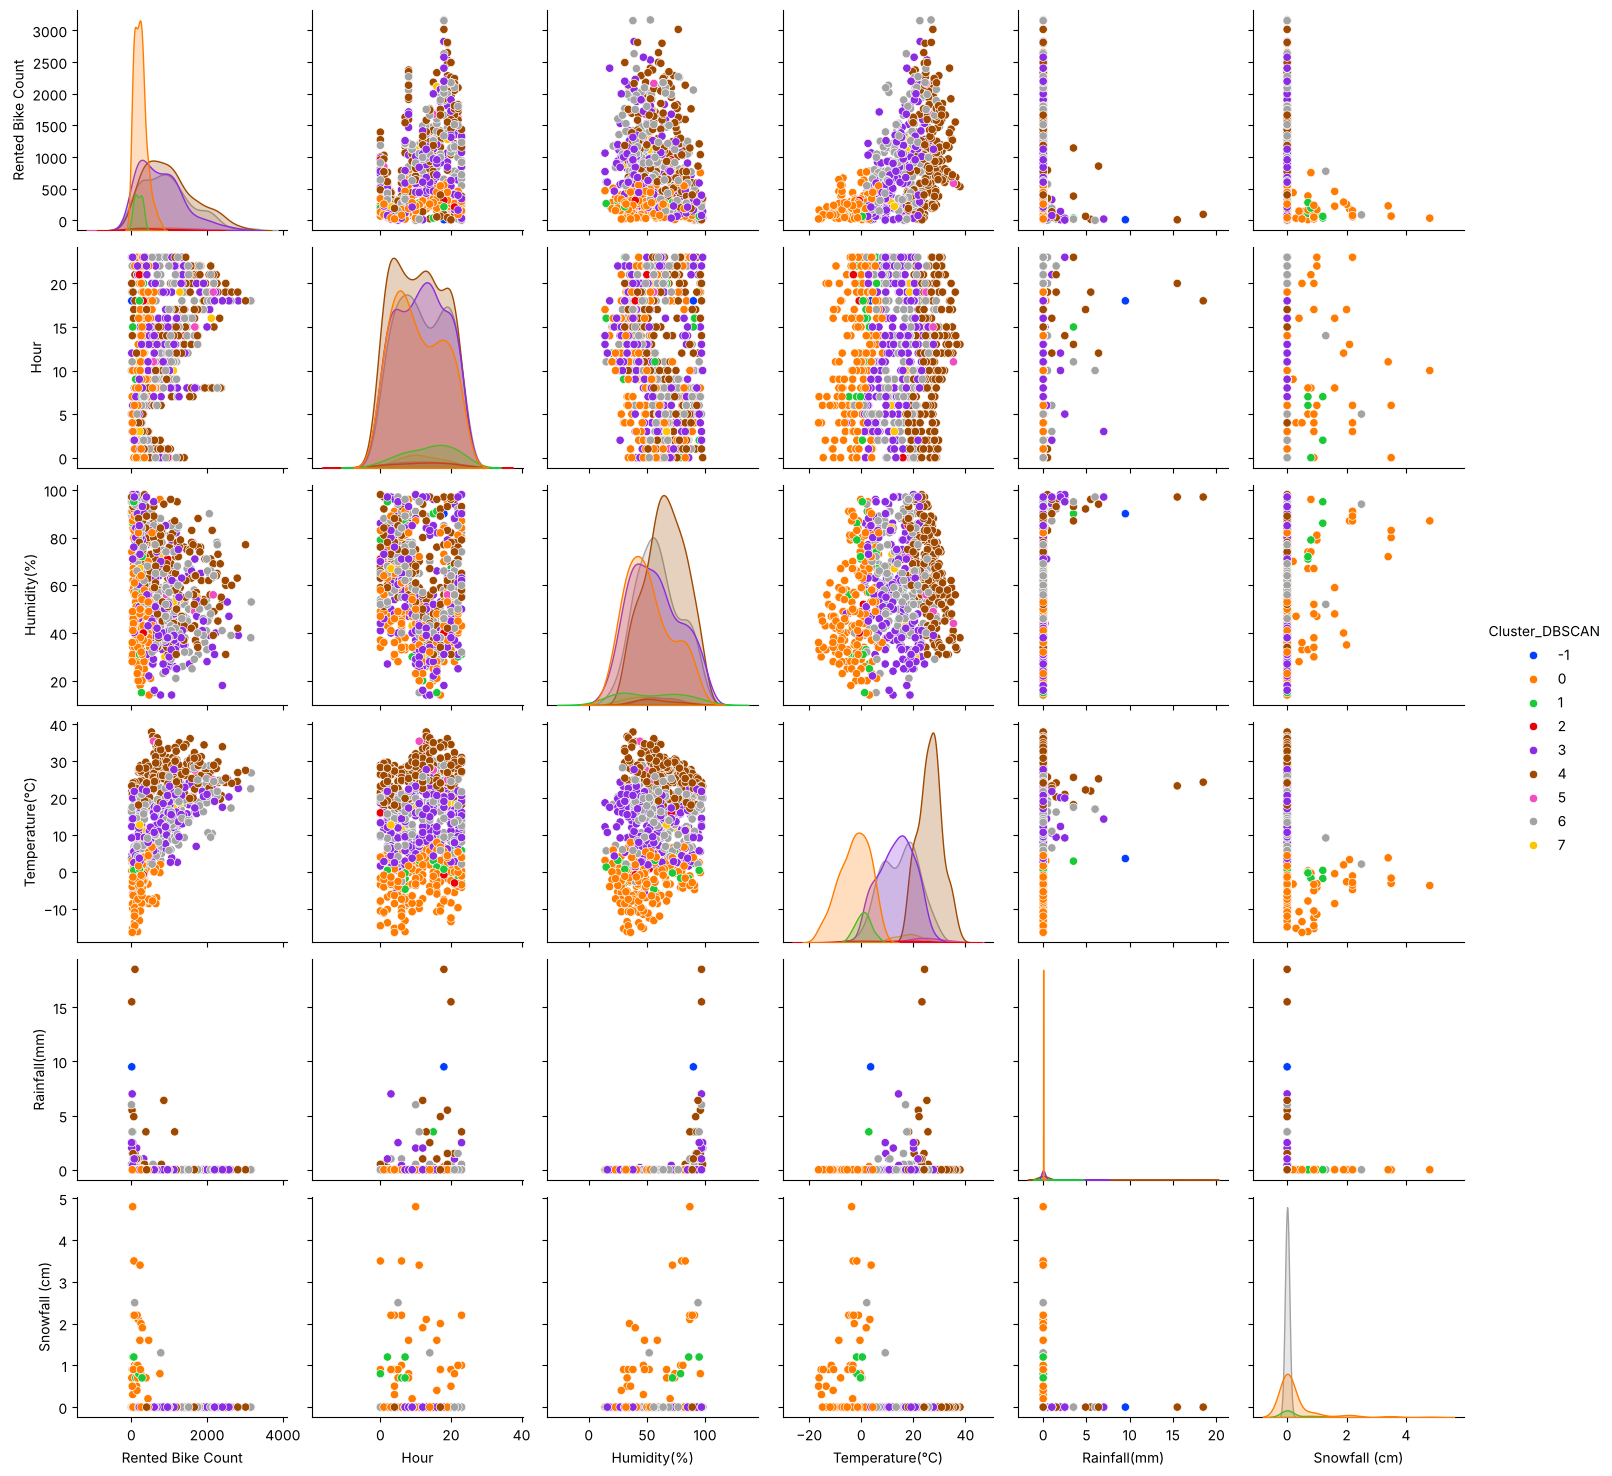

In [49]:

sns.pairplot(data_model[["Rented Bike Count"]+numerical_cols+["Cluster_DBSCAN"]].sample(800), hue="Cluster_DBSCAN", palette='bright')
plt.show()

# **Conclusion:**

En el pair plot los clusters se ven mezclados en la hora y la humedad, pero se separan en la temperatura: los clusters de invierno quedan abajo (cerca de -3°C en promedio) y los de verano arriba (cerca de 27°C), y eso se refleja también en las rentas, que son más bajas en los clusters de invierno. Esto confirma que los grupos siguen las estaciones del año. Como el pair plot usa una muestra aleatoria de 800 horas, los 14 puntos de ruido (-1) casi nunca aparecen; cuando aparecen, son horas con mucha lluvia o nieve y humedad muy alta.

#C.10 Perfil de cada cluster

In [50]:
data_model[numerical_cols+categorical_cols+["Cluster_DBSCAN"]].groupby("Cluster_DBSCAN").describe()

Hour                                                      \
                 count       mean       std  min    25%   50%    75%   max   
Cluster_DBSCAN                                                               
-1                14.0  14.000000  5.349335  4.0  10.25  12.5  18.00  21.0   
 0              1966.0  11.491862  6.922595  0.0   5.25  11.0  17.00  23.0   
 1               191.0  11.497382  6.958429  0.0   5.50  11.0  17.50  23.0   
 2                72.0  11.500000  6.970764  0.0   5.75  11.5  17.25  23.0   
 3              2085.0  11.504077  6.926583  0.0   6.00  12.0  18.00  23.0   
 4              2159.0  11.495600  6.922372  0.0   5.50  11.0  17.00  23.0   
 5                48.0  11.500000  6.995439  0.0   5.75  11.5  17.25  23.0   
 6              1834.0  11.522901  6.922671  0.0   6.00  12.0  18.00  23.0   
 7                96.0  11.500000  6.958524  0.0   5.75  11.5  17.25  23.0   

               Humidity(%)                                                 \
                     count       mean        std   min    25%   50%   75%   
Cluster_DBSCAN                                                              
-1                    14.0  95.071429   4.028061  84.0  95.25  97.0  97.0   
 0                  1966.0  49.837742  18.877336  14.0  35.00  47.0  63.0   
 1                   191.0  48.125654  22.750013  14.0  31.00  41.0  67.0   
 2                    72.0  70.004630  17.656653  33.0  55.00  71.5  85.0   
 3                  2085.0  58.847562  22.033741  10.0  42.00  58.0  77.0   
 4                  2159.0  65.075498  17.656709  21.0  52.00  65.0  79.0   
 5                    48.0  60.062500  11.613283  38.0  51.75  63.0  69.0   
 6                  1834.0  59.248637  19.070098  13.0  44.00  59.0  74.0   
 7                    96.0  52.541667  15.680304  26.0  39.75  52.5  66.0   

                     Temperature(°C)                                     \
                 max           count       mean       std   min     25%   
Cluster_DBSCAN                                                            
-1              98.0            14.0  10.792857  9.489546   0.3   2.425   
 0              97.0          1966.0  -2.775890  5.589548 -17.8  -6.600   
 1              96.0           191.0  -0.209948  3.202377  -7.1  -2.450   
 2              97.0            72.0  12.995833  9.232009  -4.0   1.900   
 3              98.0          2085.0  13.014964  6.567975  -6.6   8.100   
 4              98.0          2159.0  26.568087  4.644284  16.3  23.100   
 5              78.0            48.0  27.320833  5.431859  18.5  22.700   
 6              97.0          1834.0  13.621810  7.299576  -3.0   7.700   
 7              85.0            96.0  17.991667  3.827839  10.8  15.375   

                                    Rainfall(mm)                             \
                  50%     75%   max        count       mean        std  min   
Cluster_DBSCAN                                                                
-1               9.05  21.150  22.9         14.0  13.100000  10.199020  0.0   
 0              -2.55   1.500  10.3       1966.0   0.015870   0.190439  0.0   
 1              -0.40   2.200   6.5        191.0   0.061257   0.532093  0.0   
 2              17.40  20.300  23.1         72.0   0.159722   0.485758  0.0   
 3              13.20  17.900  29.4       2085.0   0.154101   0.794794  0.0   
 4              26.50  29.800  39.4       2159.0   0.245113   1.476276  0.0   
 5              28.15  29.675  37.4         48.0   0.020833   0.130398  0.0   
 6              12.90  19.600  30.5       1834.0   0.094329   0.658637  0.0   
 7              17.65  21.075  25.0         96.0   0.000000   0.000000  0.0   

                                          Snowfall (cm)                      \
                  25%    50%    75%   max         count      mean       std   
Cluster_DBSCAN                                                                
-1              9.025  11.25  17.75  35.0          14.0  2.264286  3.

In [51]:
# Composición de cada cluster: permite ver qué variable está separando realmente los grupos
display(pd.crosstab(data_model["Cluster_DBSCAN"], data_model["Holiday"]))
display(pd.crosstab(data_model["Cluster_DBSCAN"], data_model["Seasons"]))
display(data_model.groupby("Cluster_DBSCAN")["Rented Bike Count"].agg(["count", "mean", "median"]).round(0))

Holiday,Holiday,No Holiday
Cluster_DBSCAN,,
-1,1,13
0,0,1966
1,191,0
2,72,0
3,0,2085
4,0,2159
5,48,0
6,0,1834
7,96,0


Seasons,Autumn,Spring,Summer,Winter
Cluster_DBSCAN,,,,
-1,7,3,1,3
0,0,0,0,1966
1,0,0,0,191
2,0,72,0,0
3,0,2085,0,0
4,0,0,2159,0
5,0,0,48,0
6,1834,0,0,0
7,96,0,0,0


,count,mean,median
Cluster_DBSCAN,,,
-1,14,65.0,42.0
0,1966,232.0,212.0
1,191,157.0,139.0
2,72,635.0,366.0
3,2085,751.0,605.0
4,2159,1035.0,905.0
5,48,1022.0,925.0
6,1834,926.0,856.0
7,96,948.0,900.0


# **Conclusion perfil de clusters:**

Cada cluster corresponde a una combinación de estación y festivo:

| Cluster | Estación | Tipo de día | Horas | Temperatura media | Rentas promedio por hora |
|---|---|---|---|---|---|
| 0 | Invierno | No festivo | 1,966 | -2.8°C | 233 |
| 1 | Invierno | Festivo | 191 | -0.2°C | 157 |
| 2 | Primavera | Festivo | 72 | 13.0°C | 635 |
| 3 | Primavera | No festivo | 2,085 | 13.0°C | 751 |
| 4 | Verano | No festivo | 2,159 | 26.6°C | 1,035 |
| 5 | Verano | Festivo | 48 | 27.3°C | 1,022 |
| 6 | Otoño | No festivo | 1,834 | 13.6°C | 926 |
| 7 | Otoño | Festivo | 96 | 18.0°C | 948 |
| -1 (ruido) | Varias | Mayoría no festivo | 14 | 10.8°C | 65 |

- La demanda más baja está en invierno (cerca de 200 bicicletas por hora) y la más alta en verano y otoño (más de 900).
- En invierno y primavera los festivos tienen menos demanda que los días normales, pero en verano y otoño la demanda es casi igual, porque con buen clima la gente usa la bicicleta para pasear aunque no trabaje.
- El ruido son 14 horas con clima extremo: humedad de 84% a 98%, lluvias de hasta 35 mm o nieve de hasta 8.8 cm, y casi no hay rentas (65 en promedio).

DBSCAN separa por estación y festivo porque, al escalar las dummies, dos horas de estaciones distintas quedan a una distancia de cerca de 3.3 y los festivos a cerca de 4.7, más que el epsilon de 3.2. Para el negocio esto sirve para describir 8 escenarios típicos de demanda y para identificar las horas de clima extremo como atípicas.

**4.2 Modelo predictivo (tipo, entradas, salida):**

**Tipo de modelo:** red neuronal MLP (MLPRegressor) dentro de un Pipeline, con StandardScaler para las entradas y la salida también estandarizada (TransformedTargetRegressor). El escalado se ajusta solo con los datos de entrenamiento.

**Variables de entrada:** Hour, Humidity, Temperature, Rainfall, Snowfall y las dummies de Seasons, Holiday y Day of week (18 variables).

**Variable de salida:** Rented Bike Count (bicicletas rentadas por hora).

**Por qué este modelo:** en el EDA vimos que la relación con la demanda no es lineal (la humedad tiene un rango ideal, la hora tiene dos picos y la forma del día cambia entre semana y fin de semana). Una red neuronal puede aprender esas combinaciones mejor que una regresión lineal, que con la temperatura sola solo explicaba el 36%.

**Hiperparámetros:** con búsqueda en rejilla y validación cruzada de 5 particiones, la mejor configuración fue 2 capas ocultas de 32 y 16 neuronas, activación ReLU y alpha = 0.01.

#C.11 Modelo predictivo de regresión: red neuronal (MLP) con búsqueda en rejilla

definiendo variables de entrada y variables de salida:

In [52]:
# Definimos variables de entrada incluyendo las numéricas, las cat_names filtradas y los días de la semana codificados
variables_entrada = numerical_cols + cat_names + day_of_week_encoded_cols
variable_salida = "Rented Bike Count"

In [53]:
X = data_model[variables_entrada]
y = data_model[variable_salida]

In [54]:
#Ordenar los 2 datasets por fecha y hora
data_model = data_model.sort_values(["Date", "Hour"]).reset_index(drop=True)

In [55]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEMILLA = 42
# División en entrenamiento y prueba usando la asignación corregida (x = características, y = objetivo)
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=SEMILLA)
print("Entrenamiento:", X_ent.shape, "| Prueba:", X_pru.shape)

Entrenamiento: (6348, 18) | Prueba: (2117, 18)


In [56]:
# Pipeline: escalado de entradas + red neuronal; la salida también se estandariza para facilitar el entrenamiento
red = TransformedTargetRegressor(
    regressor=Pipeline([
        ("escalador", StandardScaler()),
        ("mlp", MLPRegressor(solver="adam", max_iter=2000, random_state=42)),
    ]),
    transformer=StandardScaler(),
)

# Rejilla de hiperparámetros: arquitectura (capas y neuronas), activación y regularización
rejilla = {
    "regressor__mlp__hidden_layer_sizes": [(8,), (32,), (64,), (16, 16), (32, 16), (32, 32), (32, 16, 8)],
    "regressor__mlp__activation": ["relu", "identity"],   # identity = activación lineal
    "regressor__mlp__alpha": [1e-4, 1e-2],
}

# Configuramos GridSearchCV con múltiples métricas para evaluar tanto el RMSE como el R2
metricas = {
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

busqueda = GridSearchCV(
    red,
    rejilla,
    cv=5,
    scoring=metricas,
    n_jobs=-1,
    refit="RMSE"
)
busqueda.fit(X_ent, y_ent)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"RMSE medio en validación cruzada (mejor modelo): {-busqueda.best_score_:.3f}")
print(f"R2 medio en validación cruzada (mejor modelo): {busqueda.cv_results_['mean_test_R2'][busqueda.best_index_]:.3f}")

Mejores hiperparámetros: {'regressor__mlp__activation': 'relu', 'regressor__mlp__alpha': 0.01, 'regressor__mlp__hidden_layer_sizes': (32, 16)}
RMSE medio en validación cruzada (mejor modelo): 232.741
R2 medio en validación cruzada (mejor modelo): 0.870


,capas,n_capas_ocultas,activacion,alpha,RMSE_validacion,desv_RMSE
0,"(32, 16)",2,relu,0.01,232.741,9.251
1,"(32, 16)",2,relu,0.00,235.787,6.114
2,"(32, 32)",2,relu,0.01,237.862,7.907
3,"(32, 32)",2,relu,0.00,239.776,5.274
4,"(32, 16, 8)",3,relu,0.01,265.492,12.672
5,"(32, 16, 8)",3,relu,0.00,268.326,16.022
6,"(16, 16)",2,relu,0.00,282.877,13.413
7,"(64,)",1,relu,0.01,289.873,6.710
8,"(16, 16)",2,relu,0.01,291.928,19.843
9,"(64,)",1,relu,0.00,296.526,9.943


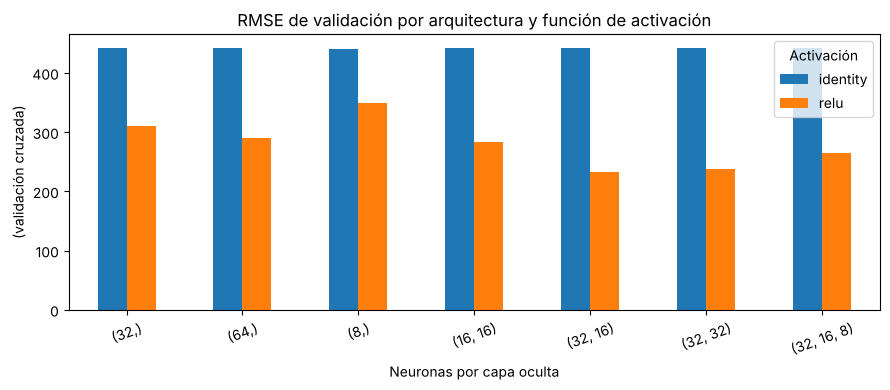

In [57]:
# Tabla de resultados de la rejilla
res = pd.DataFrame(busqueda.cv_results_)
tabla = pd.DataFrame({
    "capas": res["param_regressor__mlp__hidden_layer_sizes"].astype(str),
    "n_capas_ocultas": res["param_regressor__mlp__hidden_layer_sizes"].apply(len),
    "activacion": res["param_regressor__mlp__activation"],
    "alpha": res["param_regressor__mlp__alpha"],
    "RMSE_validacion": -res["mean_test_RMSE"],
    "desv_RMSE": res["std_test_RMSE"],
}).sort_values("RMSE_validacion").reset_index(drop=True)
display(tabla.head(10).round(3))

# Mejor RMSE por arquitectura y activación (mínimo sobre alpha)
resumen = tabla.groupby(["n_capas_ocultas", "capas", "activacion"])["RMSE_validacion"].min().unstack()
resumen.index = resumen.index.get_level_values("capas")
resumen.plot(kind="bar", figsize=(9, 4))
plt.title("RMSE de validación por arquitectura y función de activación")
plt.xlabel("Neuronas por capa oculta")
plt.ylabel("(validación cruzada)")
plt.xticks(rotation=20)
plt.legend(title="Activación")
plt.tight_layout()
plt.show()

# **Conclusion:**

La activación lineal (identity) da un RMSE de casi 440 en todas las arquitecturas, porque una red lineal funciona igual que una regresión lineal y no puede captar los picos de demanda. Con ReLU el error baja mucho en todas las arquitecturas. Las mejores son las de 2 capas con 32 neuronas en la primera: (32, 16) con RMSE de 232.7 y (32, 32) con 237.9. Agregar una tercera capa (32, 16, 8) no mejora y tiene más variación entre particiones. Antes de incluir el día de la semana el mejor RMSE era 253.6, entonces el día de la semana mejoró el error en cerca de 8%.

**4.3 Modelo prescriptivo (tipo, entradas, salida):**

**Tipo:** reglas de decisión sobre las predicciones del modelo predictivo.

**Regla:** Disponibilidad del día = pico horario máximo predicho para ese día + margen de seguridad teniendo en cuenta el error del modelo.

**Entradas:** la demanda horaria predicha por el MLP para las próximas 24 horas (con el clima pronosticado, la hora, la estación, si es festivo y el día de la semana) y el margen de seguridad calculado con los errores del modelo en el pico diario.

**Salida:** la cantidad de bicicletas que debe estar disponible cada día y la hora en que se espera el pico.

Asumimos que como no nos entregan el tamaño de la flota, no hay restricciones en este sentido y el modelo nos entregará la disponibilidad minima requerida por día. Así se cumple la regla de negocio de no tener que hacer reabastecimiento durante el día.

*La implementación y evaluación del modelo prescriptivo se desarrollará en la siguiente entrega.*


## 5. Evaluación del modelo

### RESPUESTA DEL ESTUDIANTE: 5. Evaluación

#### C.12 Evaluación del modelo de regresión

RMSE = 227.392 | MAE = 147.757 | R2 = 0.869
RMSE de la línea base (media): 628.613


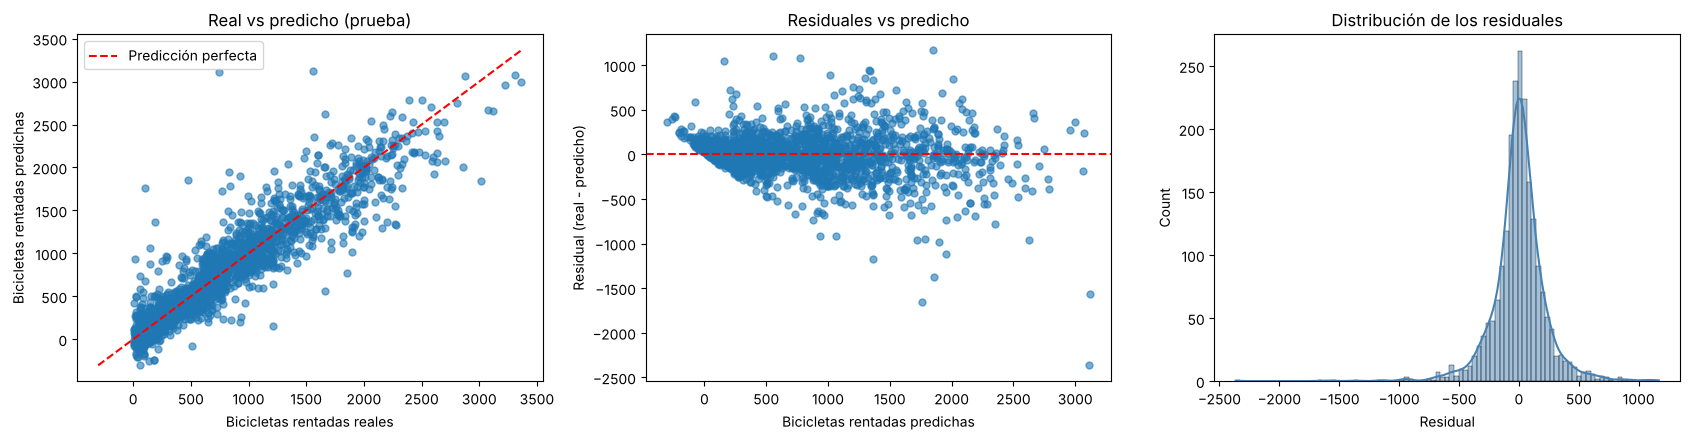

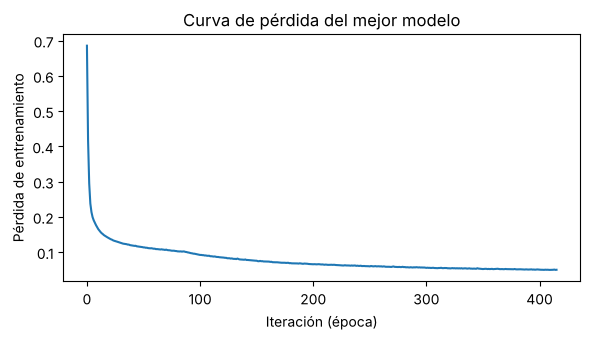

In [58]:
# Predicción sobre el conjunto de prueba con el mejor modelo
mejor_modelo = busqueda.best_estimator_
y_pred = mejor_modelo.predict(X_pru)

rmse = np.sqrt(mean_squared_error(y_pru, y_pred))
mae  = mean_absolute_error(y_pru, y_pred)
r2   = r2_score(y_pru, y_pred)
print(f"RMSE = {rmse:.3f} | MAE = {mae:.3f} | R2 = {r2:.3f}")

# Línea base: predecir siempre la media del entrenamiento (un modelo útil debe superarla)
rmse_base = np.sqrt(mean_squared_error(y_pru, np.full(len(y_pru), y_ent.mean())))
print(f"RMSE de la línea base (media): {rmse_base:.3f}")

# Valores reales vs predichos, residuales y su distribución
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

ejes[0].scatter(y_pru, y_pred, alpha=0.6, s=25)
lim = [min(y_pru.min(), y_pred.min()), max(y_pru.max(), y_pred.max())]
ejes[0].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[0].set_title("Real vs predicho (prueba)")
ejes[0].set_xlabel("Bicicletas rentadas reales")
ejes[0].set_ylabel("Bicicletas rentadas predichas")
ejes[0].legend()

residuales = y_pru - y_pred
ejes[1].scatter(y_pred, residuales, alpha=0.6, s=25)
ejes[1].axhline(0, color="r", linestyle="--")
ejes[1].set_title("Residuales vs predicho")
ejes[1].set_xlabel("Bicicletas rentadas predichas")
ejes[1].set_ylabel("Residual (real - predicho)")

sns.histplot(residuales, kde=True, ax=ejes[2], color="steelblue")
ejes[2].set_title("Distribución de los residuales")
ejes[2].set_xlabel("Residual")

plt.tight_layout()
plt.show()

# Curva de pérdida de entrenamiento de la red ganadora
curva = mejor_modelo.regressor_.named_steps["mlp"].loss_curve_
plt.figure(figsize=(6, 3.5))
plt.plot(curva)
plt.title("Curva de pérdida del mejor modelo")
plt.xlabel("Iteración (época)")
plt.ylabel("Pérdida de entrenamiento")
plt.tight_layout()
plt.show()

# **Conclusion:**

En el conjunto de prueba el modelo tiene un RMSE de 227.4, un MAE de 147.8 y un R² de 0.869. Si predijéramos siempre la media el RMSE sería de 628.6, entonces el modelo reduce el error en cerca de 64%.

**Real vs predicho:** los puntos siguen bien la línea roja, pero en las horas de más demanda (más de 2,500) quedan por debajo, o sea que el modelo se queda corto en los picos más altos. También en algunas horas de muy baja demanda predice valores negativos (hasta cerca de -300), que no tienen sentido en la realidad.

**Residuales vs predicho:** los residuales están alrededor de 0, pero se abren más a medida que la predicción es mayor. Esto significa que el modelo es más preciso en horas de poca demanda y se equivoca más en las horas pico, que es justo donde más importa.

**Distribución de los residuales:** tiene forma de campana centrada en 0, entonces el modelo no tiene un sesgo general de predecir de más o de menos. Hay pocos errores grandes en las colas (más de 1,000 bicicletas).

**Curva de pérdida:** la pérdida baja muy rápido en las primeras 20 iteraciones y después se estabiliza cerca de 0.05, el entrenamiento se detuvo solo en cerca de 400 iteraciones porque ya no mejoraba. Como el error de validación cruzada (232.7) y el de prueba (227.4) son parecidos, no hay señales de sobreajuste.

**Criterio de negocio (1.5): bicicletas faltantes y sobrantes con y sin el modelo**

,Sin modelo (promedio por hora),Con modelo (MLP),Reducción (%)
Bicicletas faltantes,426203.1,156863.2,63.2
Bicicletas sobrantes,450899.4,155938.9,65.4
Total faltante + sobrante,877102.5,312802.2,64.3


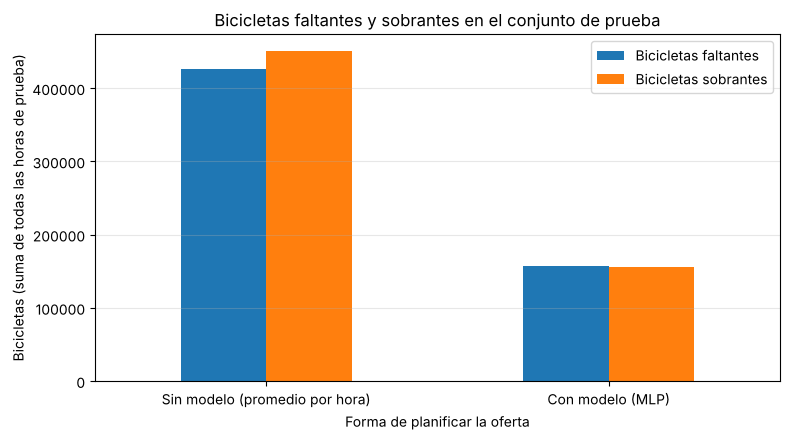

In [59]:
# Criterio de negocio (1.5): bicicletas faltantes y sobrantes con y sin el modelo
# Sin modelo: se planifica con el promedio histórico de cada hora (calculado solo con entrenamiento)
promedio_hora = y_ent.groupby(X_ent["Hour"]).mean()
plan_sin_modelo = X_pru["Hour"].map(promedio_hora).values
plan_con_modelo = y_pred

def faltante_sobrante(real, plan):
    diferencia = np.asarray(real) - np.asarray(plan)
    faltante = diferencia.clip(min=0).sum()      # demanda que no se habría cubierto
    sobrante = (-diferencia).clip(min=0).sum()   # bicicletas planificadas que no se usaron
    return faltante, sobrante

f_sin, s_sin = faltante_sobrante(y_pru, plan_sin_modelo)
f_con, s_con = faltante_sobrante(y_pru, plan_con_modelo)

criterio = pd.DataFrame({
    "Sin modelo (promedio por hora)": [f_sin, s_sin, f_sin + s_sin],
    "Con modelo (MLP)": [f_con, s_con, f_con + s_con],
}, index=["Bicicletas faltantes", "Bicicletas sobrantes", "Total faltante + sobrante"])
criterio["Reducción (%)"] = 100 * (1 - criterio["Con modelo (MLP)"] / criterio["Sin modelo (promedio por hora)"])
display(criterio.round(1))

criterio.iloc[:2, :2].T.plot(kind="bar", figsize=(8, 4.5))
plt.title("Bicicletas faltantes y sobrantes en el conjunto de prueba")
plt.xlabel("Forma de planificar la oferta")
plt.ylabel("Bicicletas (suma de todas las horas de prueba)")
plt.xticks(rotation=0)
plt.legend(title="")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# **Conclusion:**

Si planificamos con el promedio histórico de cada hora, en las horas de prueba habrían faltado 426,203 bicicletas y sobrado 450,899, en total 877,102. Con el modelo el faltante baja a 156,863 y el sobrante a 155,939, en total 312,802. Esto es una reducción del 64.3%, mucho más que la meta del 20% que pusimos en el criterio de negocio. Además el modelo queda balanceado: falta casi lo mismo que sobra.

**5.1 Métricas y justificación:**

*   RMSE (227,4): penaliza más los errores grandes. Es lo que importa, porque fallar por mucho en un pico deja a mucha gente sin bicicleta. Por eso es la métrica que usamos para escoger el mejor modelo en la búsqueda en rejilla.
*   MAE (147,8): dice en promedio por cuántas bicicletas se equivoca el modelo por hora. Es fácil de explicar al operador.
*   R² (0,869): el modelo explica cerca del 87 % de la variación de la demanda.
*   Línea base: si predijéramos siempre la media el RMSE sería 628,6, el modelo reduce el error en cerca de 64 %.
*   Validación cruzada: el RMSE fue 232,7 y el R² 0,870, parecidos a los de prueba, así que no hay señales de sobreajuste.
*   Clustering: para DBSCAN usamos el coeficiente de silueta porque no tenemos etiquetas reales para comparar. Con epsilon = 3,2 encontró 8 clusters y 14 puntos de ruido, con una silueta media de 0,476.


**5.2 ¿Responde la pregunta de negocio?**

**Sí, en la parte predictiva.** El modelo predice la demanda por hora con el clima, la hora, la estación, si es festivo y el día de la semana con un R² de 0,869 y un error medio de unas 148 bicicletas por hora. Comparado con el criterio de negocio de 1.5, el total de bicicletas faltantes + sobrantes se reduce en 64,3 % frente a planificar con el promedio de cada hora, más que la meta del 20 %. La parte prescriptiva (cuántas bicicletas tener disponibles cada día) se completará en la siguiente entrega.

**Limitaciones:**

*   La división de entrenamiento y prueba fue aleatoria por horas, no por fecha, entonces no prueba directamente la proyección a 24 horas que plantea la pregunta.
*   El clima: el modelo usa el clima real, y para predecir el día siguiente habría que usar el pronóstico, que tiene error.
*   Los datos son de un solo año.
*   El modelo se queda corto en los picos más altos y a veces predice valores negativos en horas de muy baja demanda.
*   La línea base (promedio por hora) es simple; una línea base que también tenga en cuenta la estación daría una reducción menor.


## Lista de verificación antes de entregar

- [ ] Todas las secciones (1 a 5) tienen su respuesta en este cuaderno.
- [ ] Cada gráfico y tabla tiene su análisis escrito.
- [ ] El cuaderno corre completo con Restart & Run All sin errores.
- [ ] Los comentarios del código están en español.
- [ ] El criterio de negocio (1.5) es distinto de las métricas del modelo (5.1).
- [ ] SMOTE (si se usó) se aplicó solo al conjunto de entrenamiento.
- [ ] El escalado se ajustó solo con entrenamiento (uso de Pipeline) y el conjunto de prueba se usó una sola vez.
- [ ] Se exportó a HTML y se revisó que las gráficas se vean.